# XGBoost PM2.5 — full network, five-arm ablation, continuous surfaces

Runs on the **84-sensor network** (not the 18-sensor pilot) with the station split shared with the
CNN-LSTM branch (54 train / 13 calibration / 16 test), and renders the surfaces as a **continuous
gradient** rather than AQI tiers.

Works locally (from `XGBoost/`) and on Kaggle. Training is skipped automatically when
`outputs/ablation_results.csv` already holds all five arms.

Cell-by-cell guide and glossary: **[GUIDE.md](GUIDE.md)**.


In [1]:
# ---- 0. environment: find the code, find the data, build whatever is missing -------------------
# Works with either Kaggle layout, so swapping the dataset no longer breaks the notebook:
#   (a) ONE dataset holding code + data                -> copied straight out
#   (b) a DATA-ONLY bundle + code from the public repo  -> data symlinked in, tables built here
# Locally every step is a no-op: the folder is already complete.
import glob, os, re, shutil, subprocess, sys, time

REPO = 'https://github.com/Patthethicc/urban-air.git'   # public; only used if no code dataset is attached
ROOT = '/kaggle/working/urban-air'
ON_KAGGLE = os.path.exists('/kaggle')
STATIONS = 'data/OpenAQ/locations.csv'                  # local fallback

# Set the switches BEFORE importing `data` anywhere: data.py reads them at import time to choose the
# master table and the fold file, and the module is cached afterwards.
os.environ['XGB_DATASET'] = 'full'      # the 84-sensor network (not the 18-sensor pilot)
os.environ['XGB_FOLDS'] = 'shared'      # the CNN-LSTM run's 54 / 13 / 16 station split
os.environ['XGB_WINDOW_START'] = '2023-01-01'   # CNN-LSTM arm window; empty string = all data


def _first(pattern):
    hits = glob.glob(pattern, recursive=True)
    return hits[0] if hits else None


if ON_KAGGLE:
    # 0. a zip upload may arrive unextracted -- Kaggle sometimes keeps an archive as one file.
    #    Unpack it once into a writable place; the search below then finds OpenAQ where it expects.
    if not glob.glob('/kaggle/input/**/OpenAQ', recursive=True):
        _zips = glob.glob('/kaggle/input/**/*.zip', recursive=True)
        if _zips:
            import zipfile
            _unpacked = '/kaggle/working/_bundle'
            os.makedirs(_unpacked, exist_ok=True)
            with zipfile.ZipFile(_zips[0]) as _z:
                _z.extractall(_unpacked)
            print('unpacked', _zips[0], '->', _unpacked)

    # 1. code: a dataset that holds the pipeline, else a clone of the repository.
    #    The repo keeps the pipeline one level down (urban-air/xgboost/), so CHDIR to wherever
    #    run_pipeline.py actually is. Everything below uses relative paths, so this is all it takes.
    hit = _first('/kaggle/input/**/run_pipeline.py')
    if hit:
        shutil.copytree(os.path.dirname(hit), ROOT, dirs_exist_ok=True)
        CODE = ROOT
    else:
        subprocess.run(['git', 'clone', '--depth', '1', REPO, ROOT], check=True)
        inner = glob.glob(os.path.join(ROOT, '**', 'run_pipeline.py'), recursive=True)
        # a repository can hold more than one run_pipeline.py; prefer the folder that is actually the
        # pipeline (it must have data.py beside run_pipeline.py, and the preprocessing package).
        good = [os.path.dirname(p) for p in inner
                if os.path.exists(os.path.join(os.path.dirname(p), 'data.py'))]
        if not good:
            raise SystemExit('repo cloned, but no run_pipeline.py with data.py beside it was found')
        CODE = good[0]
    os.chdir(CODE)
    sys.path.insert(0, CODE)          # make `import data` unambiguous

    # Fail loudly if `data` resolved to something that is not the pipeline module: a stray `data/`
    # folder can be imported as an empty namespace package, which otherwise surfaces much later as
    # "module 'data' has no attribute 'ROOT'" with no clue where it came from.
    import data as _probe
    if not hasattr(_probe, 'ROOT'):
        raise SystemExit(
            'imported %r instead of the pipeline data.py (code folder: %s).\n'
            'Attach a dataset that contains the code -- run_pipeline.py AND data.py in the same folder.'
            % (getattr(_probe, '__file__', _probe), CODE))

    # 2. data: shipped beside the code, or a separate raw bundle (OpenAQ/, QC Data Converted/,
    #    Morphology/master_raster_v2.tif). Symlinks keep /kaggle/input read-only.
    if not (os.path.isdir('data') and os.listdir('data')):
        openaq = (_first('/kaggle/input/**/OpenAQ')
                  or _first('/kaggle/working/_bundle/**/OpenAQ'))   # the zip fallback unpacks here
        if not openaq:
            raise SystemExit('no data found: attach the dataset that contains OpenAQ/')
        bundle = os.path.dirname(openaq)
        print('data bundle:', bundle)
        os.makedirs('data', exist_ok=True)
        # link EVERYTHING the bundle provides: raw folders, the raster, any prebuilt table, and
        # .tile_cache. Whatever is present is used; whatever is missing gets built in step 3.
        BIG = 20 * 1024 * 1024
        for entry in sorted(os.listdir(bundle)):
            src_e, dst = os.path.join(bundle, entry), os.path.join('data', entry)
            if os.path.exists(dst):
                continue
            # A staged run rewrites fold_partitions/patch_stats/imputed_*/ingest_report, and writing
            # through a symlink into /kaggle/input fails with EROFS -- so small files are COPIED.
            # Directories and the two big read-only inputs (master 171 MB, raster 87 MB) are linked.
            if os.path.isdir(src_e) or os.path.getsize(src_e) > BIG:
                os.symlink(src_e, dst)
            else:
                shutil.copy2(src_e, dst)
        # The cache folder may be spelled differently in a hand-built bundle, and the cloned repo may
        # carry an older basemap.py that only knows one spelling. Normalise it to .tile_cache.
        for alt in ('.tilecache', 'tile_cache', 'tilecache'):
            src_alt = os.path.join('data', alt)
            dst_alt = os.path.join('data', '.tile_cache')
            if os.path.isdir(src_alt) and not os.path.exists(dst_alt):
                os.symlink(src_alt, dst_alt)
                print('tile cache linked: data/%s -> data/.tile_cache' % alt)
                break
        # the raster may sit in a Morphology/ subfolder of the original bundle
        # data.py (and every stage) opens data/master_raster_v2.tif, so that path is a CANONICAL ALIAS:
        # whichever version the dataset ships (v2, v3, ...) is linked to it. Hard-coding the version was
        # wrong -- the bundle was renamed to master_raster_v3.tif and every 10 m stage broke on it.
        tif = os.path.join('data', 'master_raster_v2.tif')
        if not os.path.exists(tif):
            def _ver_key(p):
                m = re.search(r'master_raster_v(\d+)', os.path.basename(p))
                return (int(m.group(1)) if m else 0, p)
            found = []
            for pat in (os.path.join(bundle, 'Morphology', 'master_raster_v*.tif'),
                        os.path.join(bundle, 'master_raster_v*.tif'),
                        '/kaggle/input/**/master_raster_v*.tif',
                        '/kaggle/working/_bundle/**/master_raster_v*.tif'):
                found += [p for p in glob.glob(pat, recursive=True) if os.path.isfile(p)]
            found = sorted(set(found), key=_ver_key)
            if found:
                src_tif = found[-1]                      # highest version wins
                os.symlink(src_tif, tif)
                print('raster linked from:', src_tif)
                print('  -> data/master_raster_v2.tif  (canonical alias used by data.py)')
                print('  size: %.1f MB | versions seen: %s'
                      % (os.path.getsize(src_tif) / 1e6,
                         [os.path.basename(p) for p in found]))
            else:
                print('raster NOT found; searched master_raster_v*.tif under:', bundle, '/kaggle/input')
                _m = os.path.join(bundle, 'Morphology')
                print('  Morphology/ listing:', sorted(os.listdir(_m)) if os.path.isdir(_m) else '(absent)')
                print('  bundle mtime       :', time.strftime('%Y-%m-%d %H:%M', time.localtime(os.path.getmtime(bundle))))
        for cand in (os.path.join(bundle, 'Combined Dataset', 'full_with_preinstall', 'locations.csv'),
                     os.path.join(bundle, 'locations.csv')):
            if os.path.exists(cand):
                STATIONS = cand
                break

        # The NCR boundary (maps/cnn_maps.py clips to it and labels the cities). It is generated by
        # `python -m preprocessing.boundaries` (GADM 4.1, not redistributed) and normally ships inside
        # the bundle, where the loop above already picked it up. This is only a fallback.
        bnd = os.path.join('data', 'ncr_cities.gpkg')
        if not os.path.exists(bnd):
            hits = [h for pat in (os.path.join(bundle, 'ncr_cities.gpkg'),
                                  os.path.join(bundle, 'Boundaries', 'ncr_cities.gpkg'),
                                  '/kaggle/input/**/ncr_cities.gpkg')
                    for h in glob.glob(pat, recursive=True) if os.path.isfile(h)]
            if hits:
                os.symlink(hits[0], bnd)
                print('boundary linked from:', hits[0])
            else:
                print('boundary NOT found: run `python -m preprocessing.boundaries` '
                      '(the maps render without the NCR clip and city names)')
        else:
            print('boundary: data/ncr_cities.gpkg')


    # 3. derived tables: build only what is absent (a prebuilt dataset skips both steps)
    if not os.path.exists(os.path.join('data', 'Master_DL_Ready_full.csv')):
        print('building the 500 m morphology grid ...')
        subprocess.run([sys.executable, 'build_morphology_grid.py',
                        '--raster', 'data/master_raster_v2.tif',
                        '--openaq-locations', STATIONS,
                        '--qc-locations', 'data/QC Data Converted/QC Sensor Locations.csv'],
                       check=True)
        print('building Master_DL_Ready_full.csv (~4 min) ...')
        subprocess.run([sys.executable, 'ingest_sources.py'], check=True)

    # 3b. The 10 m path needs the raster. A pruned bundle can lose `Morphology/` while still carrying
    #     the derived tables, so check here: one line at 25 s beats a rasterio traceback 80 s later.
    _tif = os.path.join('data', 'master_raster_v2.tif')
    print('raster:', os.path.basename(_tif), '| exists:', os.path.exists(_tif))
    RASTER_OK = os.path.exists(_tif)
    if not RASTER_OK:
        print('  !! master_raster_v2.tif is NOT on the mount: the 10 m grid cannot be built.')
        print('  !! bundle contents:', sorted(os.listdir(bundle)))
        print('  !! add <bundle>/Morphology/master_raster_v2.tif (86 MB) as a new dataset version.')
        print('  !! the 500 m stages run without it; section 11 will refuse to start.')

    # 4. the two packages Kaggle does not ship
    if subprocess.run([sys.executable, '-c', 'import skopt, shap'],
                      capture_output=True).returncode:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                        'scikit-optimize', 'shap'], check=True)

import data
print('root  :', data.ROOT)
print('folds :', os.path.basename(data.FOLD_JSON))
print('master:', os.path.basename(data.MASTER_CSV), '| exists:', os.path.exists(data.MASTER_CSV))
print('grid  :', os.path.basename(data.GRID_CSV), '| exists:', os.path.exists(data.GRID_CSV))
assert os.path.exists(data.MASTER_CSV), 'data table missing -- read the notes above'
assert os.path.exists(data.GRID_CSV), 'grid missing -- build_morphology_grid.py did not run'

# ---- the 10 m maps need the NCR boundary: make sure it is present even if data/ was already staged --
_bnd = os.path.join('data', 'ncr_cities.gpkg')
if not os.path.exists(_bnd):
    _hits = [q for q in glob.glob('/kaggle/input/**/ncr_cities.gpkg', recursive=True) if os.path.isfile(q)]
    if _hits:
        try:
            os.symlink(_hits[0], _bnd)
            print('boundary linked from:', _hits[0])
        except OSError as _exc:
            print('boundary link failed (%s); the maps will render without the NCR clip' % _exc)
    else:
        print('boundary NOT found under /kaggle/input: upload ncr_cities.gpkg with the data bundle')
else:
    print('boundary: data/ncr_cities.gpkg (%.0f KB)' % (os.path.getsize(_bnd) / 1024))


Cloning into '/kaggle/working/urban-air'...
Updating files: 100% (327/327), done.


data bundle: /kaggle/input/datasets/nasherdc/xgboost-data/dataexample
raster linked from: /kaggle/input/datasets/nasherdc/xgboost-data/dataexample/Morphology/master_raster_v3.tif
  -> data/master_raster_v2.tif  (canonical alias used by data.py)
  size: 81.3 MB | versions seen: ['master_raster_v2.tif', 'master_raster_v3.tif']
boundary: data/ncr_cities.gpkg
raster: master_raster_v2.tif | exists: True
root  : /kaggle/working/urban-air/xgboost
folds : fold_partitions_shared.json
master: Master_DL_Ready_full.csv | exists: True
grid  : morphology_grid_full.csv | exists: True
boundary: data/ncr_cities.gpkg (116 KB)


## 1. Data and features

`preprocessing.prep` runs on import: it merges the 500 m morphology grid onto the sensor table, builds
gap-aware hourly lags (`pm25_lag_1..4`, 24 h and 72 h rolling means/stds) and the cyclical time terms.
The 10 m raster is the *source* of the morphology; the model never sees a 10 m pixel.

In [2]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from preprocessing import prep
from preprocessing import spatial_cv
from training.ablation import ARM_FEATURES, ARM_LABELS

df_clean = prep.df_clean
MAPPING = data.SENSOR_MAP_CSV
print('rows %s | cells %d | stations %d | features %d'
      % (f'{len(df_clean):,}', df_clean['Grid_ID'].nunique(),
         df_clean['Location'].nunique(), len(prep.features)))
print('period %s .. %s' % (df_clean['DateTime'].min().date(), df_clean['DateTime'].max().date()))

Loading data...
Wrote /kaggle/working/urban-air/xgboost/data/sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
EDA cleaning: dropped 5292 sensor-floor rows (<= 0.5 ug/m3) (NYE masking off) (1,487,811 -> 1,482,519, 0.36% removed)
EDA window: kept rows from 2023-01-01 onward (1,482,519 -> 1,342,897, 9.4% removed)
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1323327, 24), y=(1323327,), unique groups=83
rows 1,323,327 | cells 83 | stations 84 | features 24
period 2023-01-03 .. 2026-10-15


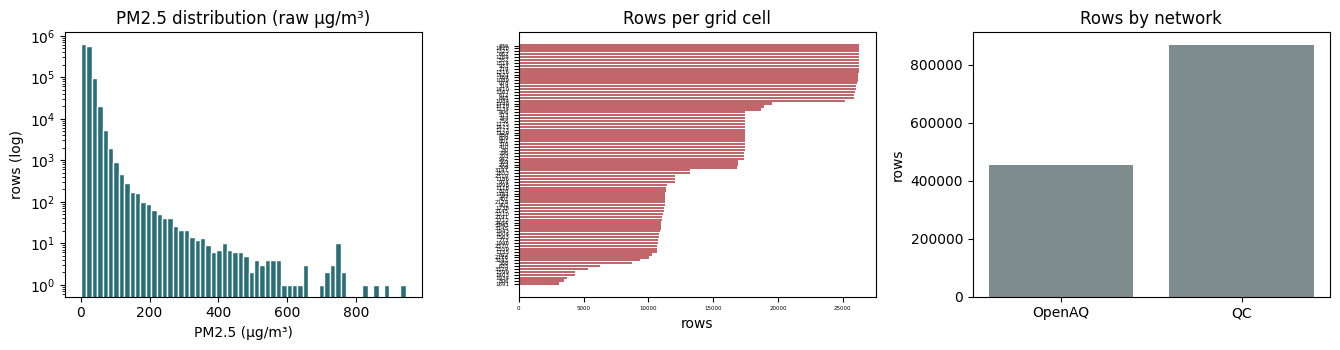

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))

axes[0].hist(df_clean['Value'], bins=60, color='#2a6f77', edgecolor='white')
axes[0].set_yscale('log')
axes[0].set_title('PM2.5 distribution (raw µg/m³)')
axes[0].set_xlabel('PM2.5 (µg/m³)'); axes[0].set_ylabel('rows (log)')

per_cell = df_clean.groupby('Grid_ID').size().sort_values()
axes[1].barh(per_cell.index.astype(str), per_cell.values, color='#c1666b')
axes[1].set_title('Rows per grid cell'); axes[1].set_xlabel('rows')
axes[1].tick_params(labelsize=4)

by_src = df_clean.groupby('source').size() if 'source' in df_clean.columns else None
if by_src is not None:
    axes[2].bar(by_src.index.astype(str), by_src.values, color='#7f8c8d')
    axes[2].set_title('Rows by network'); axes[2].set_ylabel('rows')
plt.tight_layout(); plt.show()

## 1b. EDA findings and the cleaning policy

`eda/eda_results/EDA_Report.md` audits the raw network. What each recommendation means for this model:

| EDA finding | Rows | Applied here | Effect |
|---|---|---|---|
| Sensor-floor readings (`<= 0.5 ug/m3`) | 5,292 (0.36%) | dropped, before the lags | stops a 0.0 becoming the next hour's lag; model moves ~0.3% |
| New Year's Eve fireworks (Dec 31 21:00 - Jan 1 06:00) | 1,389 (0.09%) | opt-in, `XGB_CLEAN_NYE=on` | model moves ~0.3%; reported RMSE falls 1.9% and R2 falls 0.010 only because 363 extreme rows leave the test set |
| Staggered QC cohorts (2021-2024) | -- | not a filter | the lag requires >= 2 contributing stations instead of thinning years |
| Wide-format `QC Data/` | -- | not used | the pipeline reads the long-format `QC Data Converted/` |

NYE masking is off by default: it lowers RMSE by deleting the hardest rows. `956.8 ug/m3` occurs outside
that window, so the tail is real and was not winsorised. Numbers: `experiments/eda_cleaning_impact.py`.


In [4]:
# what the cleaning did, and how much of the squared error sits in the tail
# NOTE: this cell runs BEFORE the ablation (cell ARM_FILE/BEST are defined later), so it must not depend
# on them -- an earlier version did, and raised NameError on Kaggle's first run.
import os
import numpy as np
import pandas as pd

print('cleaning policy: floor <= 0.5 ug/m3 -> %s | NYE masking -> %s'
      % (os.environ.get('XGB_CLEAN_FLOOR', 'on'), os.environ.get('XGB_CLEAN_NYE', 'off')))
print('rows in df_clean: %s' % f'{len(df_clean):,}')

# the outlier structure is a property of the TARGET, so it is available before any model is fitted
v = df_clean['Value']
for thr in (100, 150):
    print('  %.3f%% of rows have PM2.5 >= %d ug/m3   (max %.1f)'
          % (100.0 * (v >= thr).mean(), thr, v.max()))

# the share of SQUARED ERROR needs out-of-fold predictions, so only compute it if a previous run left
# them; on a clean Kaggle run this cell must pass without them
ARM_FILE_PREVIEW = {'A': 'A', 'B': 'B', 'C': 'C', 'C+': 'Cplus', 'TEXTURE': 'TEXTURE'}
_arm_now = BEST if 'BEST' in dir() else 'A'
_oof_path = os.path.join('outputs', 'oof_predictions_%s.csv' % ARM_FILE_PREVIEW[_arm_now])
if os.path.exists(_oof_path):
    _o = pd.read_csv(_oof_path, usecols=['actual', 'predicted'])
    _e2 = (_o.actual - _o.predicted) ** 2
    print('  tail share: %.3f%% of rows have actual > 150 and carry %.1f%% of the squared error'
          % (100.0 * (_o.actual > 150).mean(), 100.0 * _e2[_o.actual > 150].sum() / _e2.sum()))
else:
    print('  tail share of squared error: reported in the results section, once the ablation has run')


cleaning policy: floor <= 0.5 ug/m3 -> on | NYE masking -> off
rows in df_clean: 1,323,327
  0.169% of rows have PM2.5 >= 100 ug/m3   (max 944.0)
  0.063% of rows have PM2.5 >= 150 ug/m3   (max 944.0)
  tail share of squared error: reported in the results section, once the ablation has run


## 2. Dataset report (Deliverable 1)

In [5]:
!python run_pipeline.py --stage report
from IPython.display import Markdown, display
display(Markdown(open('outputs/dataset_report.md', encoding='utf-8').read()[:3000]))

stage: report
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
Loading data...
Wrote /kaggle/working/urban-air/xgboost/data/sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
EDA cleaning: dropped 5292 sensor-floor rows (<= 0.5 ug/m3) (NYE masking off) (1,487,811 -> 1,482,519, 0.36% removed)
EDA window: kept rows from 2023-01-01 onward (1,482,519 -> 1,342,897, 9.4% removed)
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1323327, 24), y=(1323327,), unique groups=83
wrote /kaggle/working/urban-air/xgboost/outputs/dataset_report.md
  rows 1,323,327 kept of 1,487,811; 83 cells with a sensor
done


# Dataset report (Deliverable 1)

Generated by `dataset_report.py`. Plan Section 3.3: "Descriptive statistics (Deliverable 1): rows kept
and dropped, sensors, cells, date range, missingness, feature distributions."

## 1. Rows kept and dropped

| Stage | Rows | Share |
|---|---|---|
| Raw rows in `/kaggle/working/urban-air/xgboost/data/Master_DL_Ready_full.csv` | 1,487,811 | 100% |
| With a finite `pm25_target` | 1,487,811 | 100.0% |
| **Kept** after gap-aware lag cleaning (`X`, `y`) | **1,323,327** | **88.9%** |
| Dropped: no target value | 0 | 0.0% |
| Dropped: lag/rolling window crossed a timestamp gap | 164,484 | 11.1% |

The gap-aware drop is deliberate. `Master_DL_Ready.csv` carries its own `pm25_t-1/2/3` columns, which are
naive row-shifts on irregularly-timed data; during a gap they pair a reading with one from hours earlier.
This pipeline recomputes the lags on a per-sensor hourly index instead, so a lag that would cross a gap
becomes missing and the row is dropped. The cost is the row count above; the benefit is that no lag
feature is a mislabelled stale reading.

### 1.1 Which requirement removes the rows

The filter is a conjunction, so each requirement is applied in turn. Sensors report roughly 70% of the
hours in their own span, and the 72 h rolling window needs 54 of 72 consecutive hours, so most of the
loss is caused by the longest window rather than by the short lags:

| stage | rows | lost_vs_previous |
|---|---|---|
| with a target value | 1487811 | 0 |
| + 1 h lag | 1487640 | 171 |
| + 2 h lag | 1487472 | 168 |
| + 3 h lag | 1487305 | 167 |
| + 4 h lag | 1487138 | 167 |
| + 24 h rolling mean | 1484838 | 2300 |
| + 24 h rolling sd | 1484838 | 0 |
| + 72 h rolling mean | 1479013 | 5825 |
| + 72 h rolling sd (final keep) | 1479013 | 0 |

This is the honest cost of the design choice. The alternative -- reusing the raw file's row-shifted lags
-- would keep far more rows but feed the model readings mislabelled by up to 29 hours. Whether to relax
the 72 h requirement (a shorter window, or an interpolation cap) is a modelling decision for the
write-up, not something this report should change.

## 2. Sensors and cells

| Quantity | Value |
|---|---|
| Sensors in the raw file | 84 |
| Sensors matched into the raster | 84 |
| Sensors outside the raster (dropped) | 0 |
| Raster cells in `/kaggle/working/urban-air/xgboost/data/morphology_grid_full.csv` | 3696 |
| Cells containing a sensor | 83 |

## 3. Grid cell 1749: two sensors in one cell

Grid cell **1749** holds two sensors that report at the same hours. Consequences, measured rather than assumed:

| Quantity | Value |
|---|---|
| Duplicated cell-hours | 4,355 |
| Rows in cells with duplicates | 19,518 |
| Share of kept rows | 1.5% |

Every pooled metric in this branch therefore gives that cell roughly twice the weight of a
single-sensor cell. **No aggregation is applied**, because collapsing to one row per cell-hour would
change every number already reported. The spatial-lag feature 

## 3. Spatial folds

Cells are clustered by centroid (k-means) into spatially contiguous, non-overlapping folds, so no cell
used for training is in the held-out fold — the thesis requirement (Fig. 4.16).

In [6]:
!python run_pipeline.py --stage split
!python run_pipeline.py --stage patch --force-patch
doc = spatial_cv.load_fold_map()
parts = doc['partitions']
print('train %d / calibration %d / test %d cells'
      % (len(parts['train']), len(parts['calibration']), len(parts['test'])))

stage: split
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
Loading data...
Wrote /kaggle/working/urban-air/xgboost/data/sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
EDA cleaning: dropped 5292 sensor-floor rows (<= 0.5 ug/m3) (NYE masking off) (1,487,811 -> 1,482,519, 0.36% removed)
EDA window: kept rows from 2023-01-01 onward (1,482,519 -> 1,342,897, 9.4% removed)
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1323327, 24), y=(1323327,), unique groups=83
sensor -> cell map: 84 stations, 83 cells

partitions (cells)
  test        16 cells from 16 stations
  calibration 13 cells from 13 stations
  train       54 cells

wrote /kaggle/working/urban-air/xgboost/data/fold

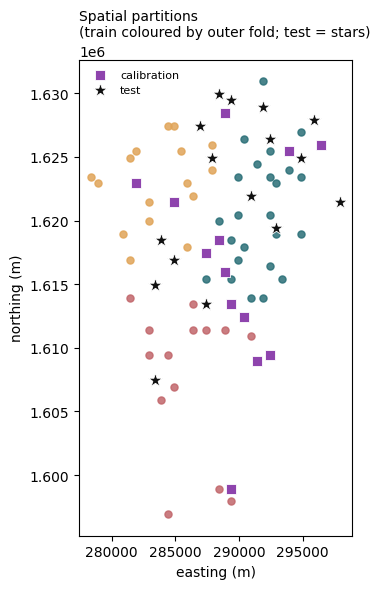

In [7]:
cent = spatial_cv.get_grid_centroids(MAPPING).set_index('Grid_ID')
outer_of = {int(c): int(f) for f, cs in doc['folds']['outer'].items() for c in cs}
palette = ['#2a6f77', '#c1666b', '#e0a458']

fig, ax = plt.subplots(figsize=(6.4, 6.0))
for name, col, mk in [('train', None, 'o'), ('calibration', '#8e44ad', 's'), ('test', '#111111', '*')]:
    cs = parts[name]
    pts = cent.loc[[c for c in cs if c in cent.index]]
    if name == 'train':
        for ci, cc in enumerate(pts.index):
            ax.scatter(pts.loc[cc, 'cx'], pts.loc[cc, 'cy'], s=26,
                       color=palette[outer_of.get(int(cc), 0) % 3], marker='o', alpha=0.85)
    else:
        ax.scatter(pts['cx'], pts['cy'], s=110 if name == 'test' else 60, color=col,
                   marker=mk, edgecolor='white', linewidth=0.6, label=name, zorder=5)
ax.set_aspect('equal'); ax.set_xlabel('easting (m)'); ax.set_ylabel('northing (m)')
ax.set_title('Spatial partitions\n(train coloured by outer fold; test = stars)', fontsize=10, loc='left')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 4. Five-arm ablation

`A` time only · `B` morphology+time · `C` full · `C+` full+spatial lag · `TEXTURE` full+10 m patch
statistics. Nested spatial CV: 3 outer folds, 3 inner folds, Bayesian (GP-EI) hyperparameter search.

In [8]:
ARMS = ['A', 'B', 'C', 'C+', 'TEXTURE']
_p = 'outputs/ablation_results.csv'
HAVE_RESULTS = False
if os.path.exists(_p):
    _r = pd.read_csv(_p)
    _per = _r.groupby('arm').size()
    HAVE_RESULTS = set(ARMS) <= set(_r['arm']) and all(_per.get(a, 0) >= 3 for a in ARMS)
    print('existing folds per arm:', {a: int(_per.get(a, 0)) for a in ARMS})
print('reuse existing results:', HAVE_RESULTS)

reuse existing results: False


In [9]:
# The thesis setting: 20 Bayesian trials per arm. `--row-stride 4` tunes on every 4th training row,
# which makes the search ~3x cheaper without touching the validation rows (early stopping is
# unaffected). Set ROW_STRIDE = 1 to reproduce the published search exactly.
N_TRIALS = 20
ROW_STRIDE = 4

if HAVE_RESULTS:
    print('skipping training: all 5 arms x 3 folds already in outputs/ablation_results.csv')
else:
    !python run_pipeline.py --stage ablation --arms A B C C+ TEXTURE --n-trials {N_TRIALS} --row-stride {ROW_STRIDE}

stage: ablation
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
Loading data...
Wrote /kaggle/working/urban-air/xgboost/data/sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
EDA cleaning: dropped 5292 sensor-floor rows (<= 0.5 ug/m3) (NYE masking off) (1,487,811 -> 1,482,519, 0.36% removed)
EDA window: kept rows from 2023-01-01 onward (1,482,519 -> 1,342,897, 9.4% removed)
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1323327, 24), y=(1323327,), unique groups=83

=== arm A TIME_ONLY (18 features) [arm 1/5] ===
    3 outer fold(s): [np.int64(0), np.int64(1), np.int64(2)]
    fold 0: tuning (20 trials x 3 inner folds, 370,399 train rows, stride 4) ...
      trial  1/20  in

## 4b. Untuned control

Arm C with XGBoost's defaults, no search. Measures what the 20 trials bought; writes to `outputs/untuned/`, so the tuned results stay intact.


In [10]:
# ---- untuned control: same folds, default parameters, no search --------------------------------
import pandas as pd

UNTUNED_DIR = 'outputs/untuned'
!python run_pipeline.py --stage ablation --arms C --untuned --ablation-out-dir {UNTUNED_DIR}

tuned = pd.read_csv('outputs/ablation_summary.csv').set_index('arm')
unt = pd.read_csv(UNTUNED_DIR + '/ablation_summary.csv').set_index('arm')
cmp = pd.DataFrame({
    'tuned pooled R2': tuned.loc['C', ['pooled_r2']],
    'untuned pooled R2': unt.loc['C', ['pooled_r2']],
}).T
cmp['pooled_rmse'] = [tuned.loc['C', 'pooled_rmse'], unt.loc['C', 'pooled_rmse']]
cmp['pooled_mae'] = [tuned.loc['C', 'pooled_mae'], unt.loc['C', 'pooled_mae']]
print(cmp.round(4).to_string())
gain = float(tuned.loc['C', 'pooled_r2'] - unt.loc['C', 'pooled_r2'])
print('\nsearch gain on arm C: %+.4f pooled R2  (tuned - untuned)' % gain)
if gain > 0.005:
    print('  the search earned its trials')
elif gain < -0.005:
    print('  the search HURT: report this honestly -- the tuned arm is worse than the defaults')
else:
    print('  the search bought nothing measurable on this arm')


stage: ablation
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
Loading data...
Wrote /kaggle/working/urban-air/xgboost/data/sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
EDA cleaning: dropped 5292 sensor-floor rows (<= 0.5 ug/m3) (NYE masking off) (1,487,811 -> 1,482,519, 0.36% removed)
EDA window: kept rows from 2023-01-01 onward (1,482,519 -> 1,342,897, 9.4% removed)
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1323327, 24), y=(1323327,), unique groups=83

=== arm C FULL (24 features) [arm 1/1] ===
    3 outer fold(s): [np.int64(0), np.int64(1), np.int64(2)]
    fold 0: FIXED parameters, no search (370,399 train rows, stride 1) ...
    fold 0: FIXED, inner_rmse 0.

In [11]:
# the ablation writes this; without it there is no BEST arm to score
if not os.path.exists('outputs/ablation_summary.csv'):
    raise SystemExit('outputs/ablation_summary.csv missing -- run the ablation cell above '
                     '(five arms, ~2.5 h) before this one')
# arm names are not safe filenames ('C+' -> 'Cplus'), and BEST is used by later cells
summary = pd.read_csv('outputs/ablation_summary.csv').sort_values('pooled_r2', ascending=False)
BEST = summary['arm'].iloc[0]
ARM_FILE = {'A': 'A', 'B': 'B', 'C': 'C', 'C+': 'Cplus', 'TEXTURE': 'TEXTURE'}
print(summary[['arm','label','n_features','pooled_rmse','pooled_mae','pooled_r2',
               'r2_mean','r2_sd','oof_rows']].round(3).to_string(index=False))
print('\nwinning arm:', BEST)


    arm               label  n_features  pooled_rmse  pooled_mae  pooled_r2  r2_mean  r2_sd  oof_rows
      A         A TIME_ONLY          18        9.148       3.849      0.575    0.605  0.088    794073
      C              C FULL          24        9.217       3.854      0.568    0.600  0.097    794073
TEXTURE           D TEXTURE          59        9.238       3.866      0.566    0.598  0.097    794073
     C+ C+ FULL+spatial lag          27        9.350       3.842      0.556    0.582  0.083    794073
      B        B MORPH_TIME          15       14.326       8.474     -0.043   -0.036  0.066    794073

winning arm: A


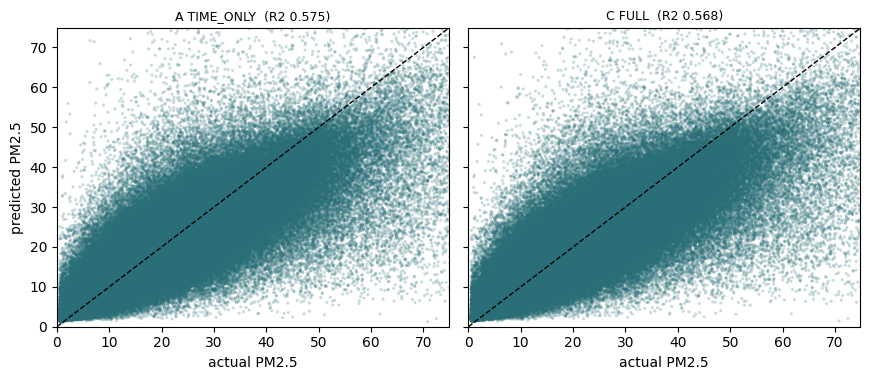

In [12]:
shown = list(dict.fromkeys(['A', 'C', BEST]))      # dedupe if BEST is A or C
oof = {a: pd.read_csv('outputs/oof_predictions_%s.csv' % ARM_FILE[a]) for a in shown}
lims = [0, float(np.nanpercentile(oof[shown[0]]['actual'], 99.5))]

fig, axes = plt.subplots(1, len(shown), figsize=(4.4 * len(shown), 3.9), sharex=True, sharey=True,
                         squeeze=False)
for ax, a in zip(axes.ravel(), shown):
    d = oof[a]
    ax.scatter(d['actual'], d['predicted'], s=5, alpha=0.25, color='#2a6f77', edgecolors='none')
    ax.plot(lims, lims, 'k--', lw=1)
    r2 = summary.set_index('arm').loc[a, 'pooled_r2']
    ax.set_title('%s  (R2 %.3f)' % (ARM_LABELS[a], r2), fontsize=9)
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel('actual PM2.5')
axes.ravel()[0].set_ylabel('predicted PM2.5')
plt.tight_layout(); plt.show()


## 5. The reserved test stations

Never used for training, tuning or calibration. This is the headline accuracy.

In [13]:
!python run_pipeline.py --stage test --test-arm {BEST} --test-seeds 42 43 44
print(pd.read_csv('outputs/test_metrics_all.csv')[['arm','stations','rmse','mae','r2','ia',
                                                   'pearson_r','bias','within_5','within_10']]
      .round(3).to_string(index=False))

stage: test
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
Loading data...
Wrote /kaggle/working/urban-air/xgboost/data/sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
EDA cleaning: dropped 5292 sensor-floor rows (<= 0.5 ug/m3) (NYE masking off) (1,487,811 -> 1,482,519, 0.36% removed)
EDA window: kept rows from 2023-01-01 onward (1,482,519 -> 1,342,897, 9.4% removed)
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1323327, 24), y=(1323327,), unique groups=83
arm A: fitting on 54 training cells (794,073 rows), scoring 16 test cells (293,957 rows)
  hyperparameters: {'colsample_bytree': 0.762, 'gamma': 0.233, 'learning_rate': 0.039, 'max_depth': 4, 'min_child_weight': 1.0,

## 6. Spatial bias in the out-of-fold residuals (Section 4.4.3)

If errors cluster geographically, a purely aspatial model is missing something the map could supply.
Moran's I on the per-cell mean residual answers that directly.

In [14]:
from preprocessing.spatial_bias import (aggregate_residuals_by_grid, build_knn_weights,
                                        global_morans_i, local_morans_i)

oof_df = pd.read_csv(f'outputs/oof_predictions_{ARM_FILE[BEST]}.csv')
grid_res = aggregate_residuals_by_grid(oof_df, MAPPING)
print('aggregated to %d grid cells' % len(grid_res))

w = build_knn_weights(grid_res, k=4)
I, p_value = global_morans_i(grid_res['residual'].values, w)
print("Global Moran's I: %+.3f   (p = %.3f, %d cells)" % (I, p_value, len(grid_res)))

if p_value < 0.05:
    lisa = pd.concat([grid_res[['Grid_ID','residual']].reset_index(drop=True),
                      local_morans_i(grid_res['residual'].values, w)], axis=1)
    print(lisa.sort_values('p_sim').head(10).to_string(index=False))
else:
    print('-> no statistically significant spatial clustering of residuals at this alpha')

aggregated to 54 grid cells
Global Moran's I: +0.093   (p = 0.272, 54 cells)
-> no statistically significant spatial clustering of residuals at this alpha


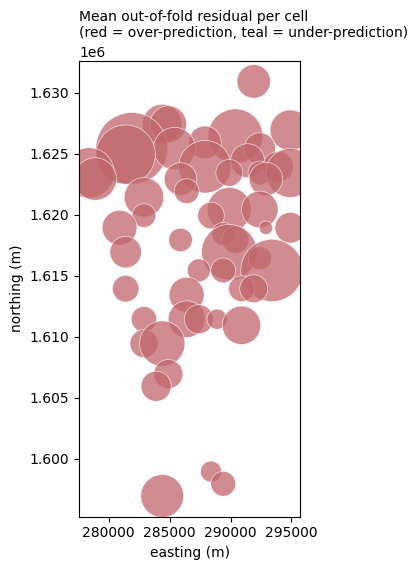

In [15]:
fig, ax = plt.subplots(figsize=(6.2, 5.8))
sizes = 80 + 2600 * (grid_res['residual'].abs() / grid_res['residual'].abs().max())
colors = np.where(grid_res['residual'] >= 0, '#c1666b', '#2a6f77')
ax.scatter(grid_res['cx'], grid_res['cy'], s=sizes, c=colors, alpha=0.75, edgecolor='white',
           linewidth=0.5)
ax.set_aspect('equal')
ax.set_title('Mean out-of-fold residual per cell\n(red = over-prediction, teal = under-prediction)',
             fontsize=10, loc='left')
ax.set_xlabel('easting (m)'); ax.set_ylabel('northing (m)')
plt.tight_layout(); plt.show()

## 7. Prediction intervals — GeoCP, matched to the CNN-LSTM settings

Kernel × bandwidth grid `[2000, 5000, 10000, 20000, inf]` with gaussian and exponential kernels, selected
by leave-one-station-out on the calibration stations, `finite_sample_correction = False`.

In [16]:
!python run_pipeline.py --stage geocp --geocp-profile shared --max-cal 6000 --max-eval 20000

stage: geocp
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
Loading data...
Wrote /kaggle/working/urban-air/xgboost/data/sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
EDA cleaning: dropped 5292 sensor-floor rows (<= 0.5 ug/m3) (NYE masking off) (1,487,811 -> 1,482,519, 0.36% removed)
EDA window: kept rows from 2023-01-01 onward (1,482,519 -> 1,342,897, 9.4% removed)
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1323327, 24), y=(1323327,), unique groups=83
test rows subsampled for evaluation: 20,000 of 293,957 (seed 42)
calibration records subsampled: 6,000 of 235,297 (seed 42)

=== leave-one-calibration-station-out over kernels x bandwidths ===
  gaussian     done
  

In [17]:
import json
g = json.load(open('outputs/geocp_shared/geocp.json'))
print('selected kernel :', g['selected']['kernel'], '@', g['selected']['bandwidth_m'], 'm')
print('LOSO coverage   : %.3f' % g['selected']['loso_coverage'])
print('TEST coverage   : %.4f  (target %.2f)' % (g['test']['coverage'], g['test']['target_coverage']))
print('mean width      : %.2f ug/m3' % g['test']['mean_width'])
cand = pd.read_csv('outputs/geocp_shared/geocp_candidates.csv')
display(cand.round(3).sort_values('loso_coverage', ascending=False).head(8))


selected kernel : exponential @ 2000.0 m
LOSO coverage   : 0.892
TEST coverage   : 0.9042  (target 0.90)
mean width      : 15.30 ug/m3


,kernel,bandwidth_m,loso_coverage,loso_worst_fold_coverage,loso_mean_width
1,gaussian,2000.0,0.893,0.772,16.322
0,exponential,2000.0,0.892,0.772,15.946
8,exponential,NaN,0.891,0.735,15.850
7,gaussian,NaN,0.891,0.735,15.850
2,exponential,5000.0,0.890,0.741,15.635
5,exponential,20000.0,0.890,0.735,15.778
6,gaussian,20000.0,0.890,0.735,15.824
3,gaussian,5000.0,0.889,0.741,15.665


## 8. The model artifact

In [18]:
!python run_pipeline.py --stage save
print(open('outputs/artifacts/latest/features.json', encoding='utf-8').read()[:400])

stage: save
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
Loading data...
Wrote /kaggle/working/urban-air/xgboost/data/sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
EDA cleaning: dropped 5292 sensor-floor rows (<= 0.5 ug/m3) (NYE masking off) (1,487,811 -> 1,482,519, 0.36% removed)
EDA window: kept rows from 2023-01-01 onward (1,482,519 -> 1,342,897, 9.4% removed)
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1323327, 24), y=(1323327,), unique groups=83
  deploying arm A, 18 features, fold 1's hyperparameters, n_estimators=298
  fitted on 794,073 rows from 54 training cells
  artifact written to /kaggle/working/urban-air/xgboost/outputs/artifacts/latest
done
{
  "fe

## 9. Interpretability — gain importance and TreeSHAP

Grad-CAM does not apply to a tree ensemble (there is no convolutional feature map to attribute), so
attribution uses TreeSHAP, which is exact and additive for tree models.

In [19]:
import joblib
model = joblib.load('outputs/artifacts/latest/model.joblib')
gain = pd.Series(model.get_booster().get_score(importance_type='gain'))
gain.index = [int(i[1:]) for i in gain.index]          # 'f0' -> 0
gain = gain.reindex(range(len(ARM_FEATURES[BEST]))).fillna(0)
gain.index = ARM_FEATURES[BEST]
gain = (gain / gain.sum()).sort_values()
print(gain.tail(10).round(3).to_string())


pm25_roll72_std     0.004
hour_x_bldg_dens    0.005
hour_cos            0.007
pm25_roll72_mean    0.014
hour_sin            0.015
pm25_lag_3          0.029
pm25_diff_1_2       0.051
pm25_roll24_mean    0.077
pm25_lag_2          0.317
pm25_lag_1          0.464


gain share of the 6 morphological features: 0.0%


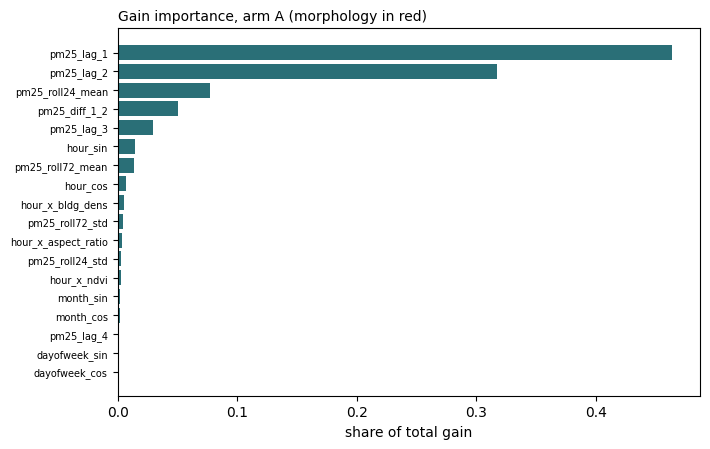

In [20]:
morph_cols = ['bh_mean','bh_stdev','ndvi_mean','bldg_dens','aspect_ratio_mean','street_width_mean']
present = [c for c in morph_cols if c in gain.index]
morph_share = 100.0 * gain[present].sum() if present else 0.0
print('gain share of the 6 morphological features: %.1f%%' % morph_share)

fig, ax = plt.subplots(figsize=(7.2, 4.6))
colors = ['#c0392b' if f in morph_cols else '#2a6f77' for f in gain.index]
ax.barh(range(len(gain)), gain.values, color=colors)
ax.set_yticks(range(len(gain))); ax.set_yticklabels(gain.index, fontsize=7)
ax.set_xlabel('share of total gain')
ax.set_title('Gain importance, arm %s (morphology in red)' % BEST, fontsize=10, loc='left')
plt.tight_layout(); plt.show()


In [21]:
!python run_pipeline.py --stage figures --figures-arm {BEST}

stage: figures
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
=== figures -> /kaggle/working/urban-air/xgboost/outputs/figures/A ===
  using predictions_test_A.csv
  pred_vs_obs.png              ok
  residual_hist.png            ok
  accuracy_by_station.png      ok
  timeseries_sample.png        ok
  error_vs_concentration.png   ok
  geocp_coverage.png           source: geocp_shared
  geocp_coverage.png           ok
Loading data...
Wrote /kaggle/working/urban-air/xgboost/data/sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
EDA cleaning: dropped 5292 sensor-floor rows (<= 0.5 ug/m3) (NYE masking off) (1,487,811 -> 1,482,519, 0.36% removed)
EDA window: kept rows from 2023-01-01 onward (1,482,519 -> 1,342,897, 9.4% removed)
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, 

shap_beeswarm.png


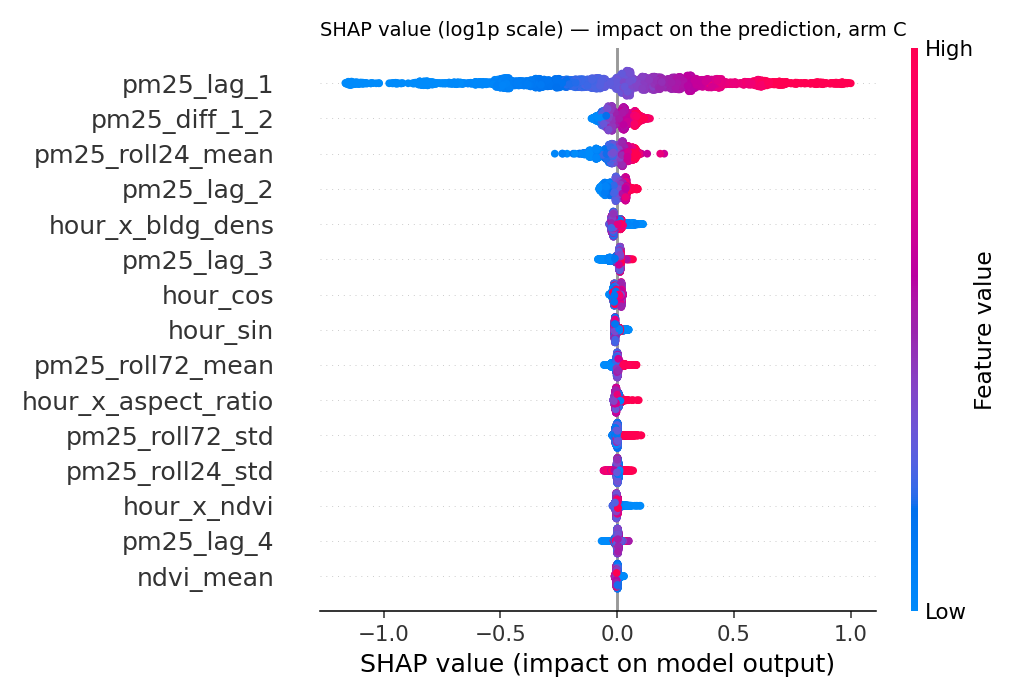

shap_waterfall.png


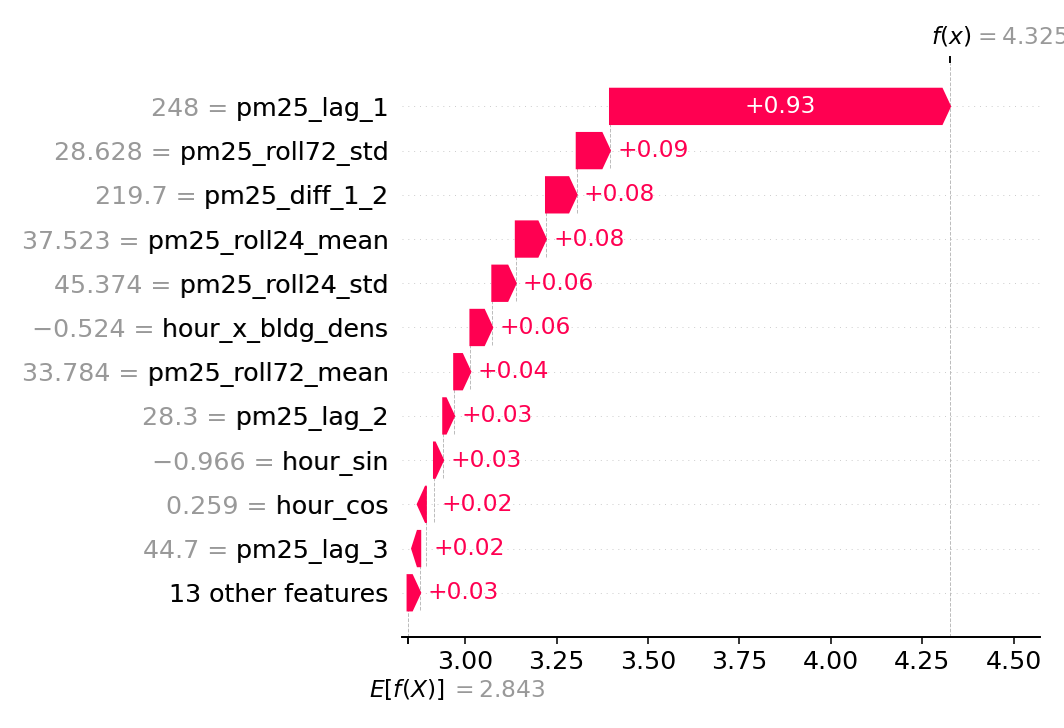

shap_importance.png


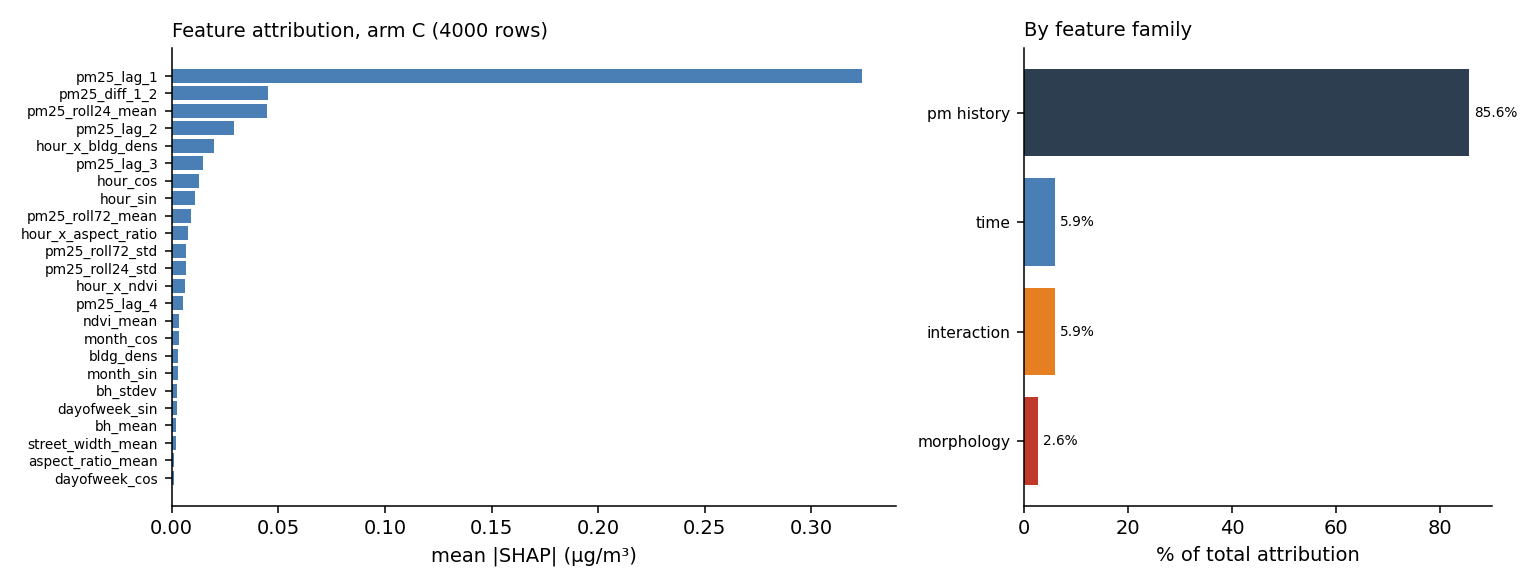

pred_vs_obs.png


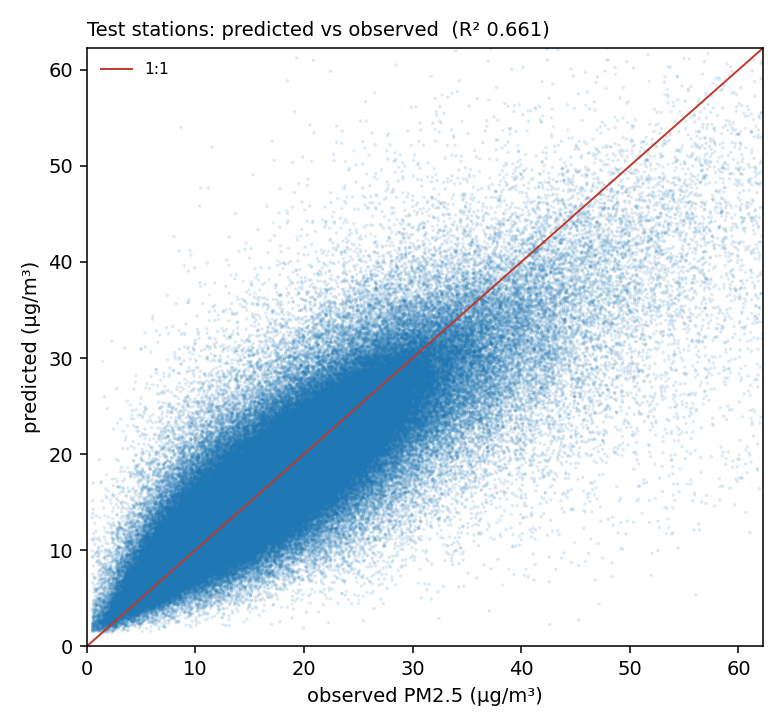

error_vs_concentration.png


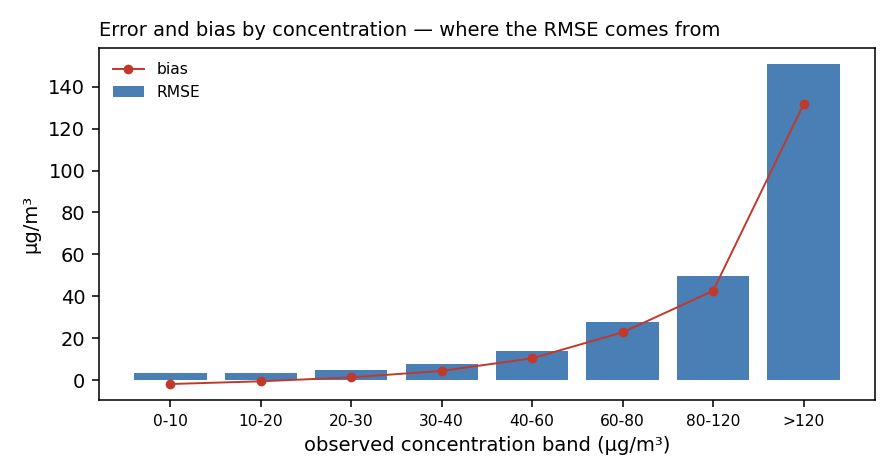

accuracy_by_station.png


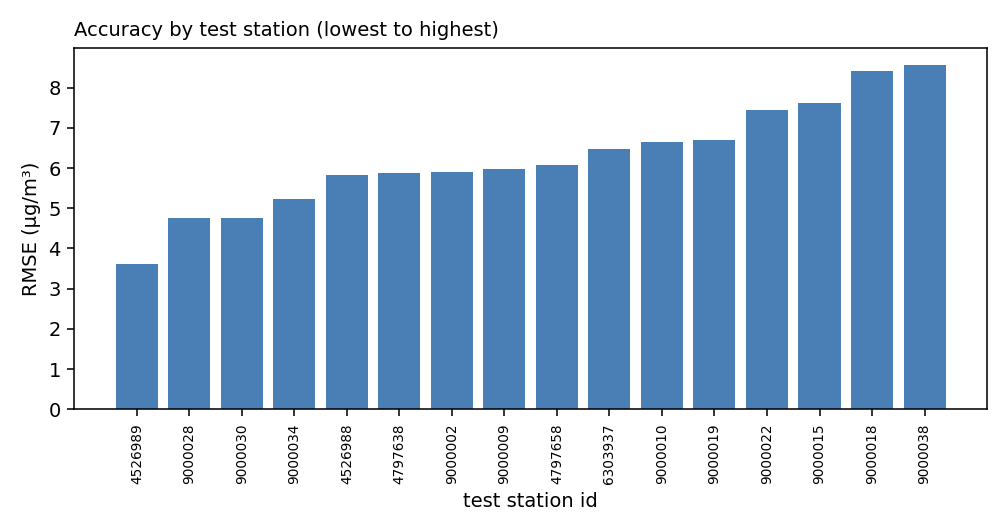

residual_hist.png


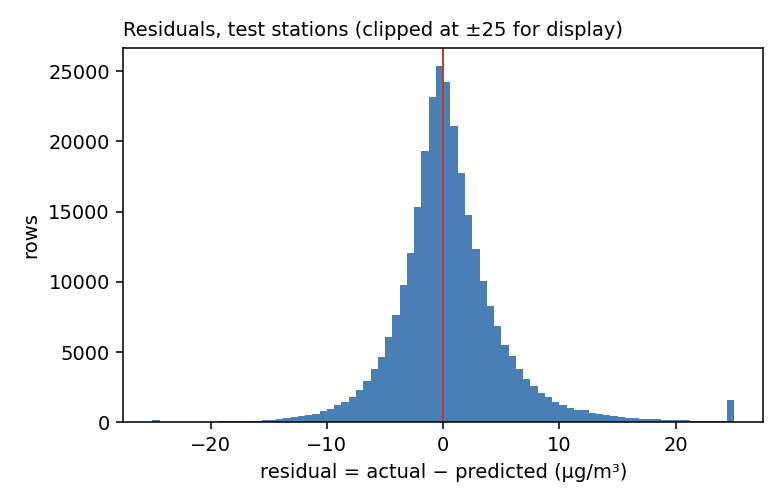

timeseries_sample.png


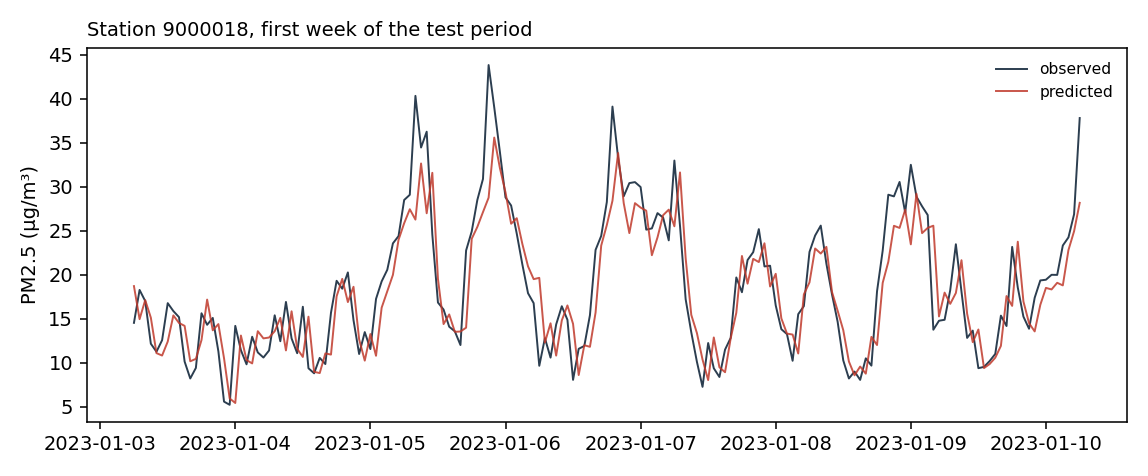

geocp_coverage.png


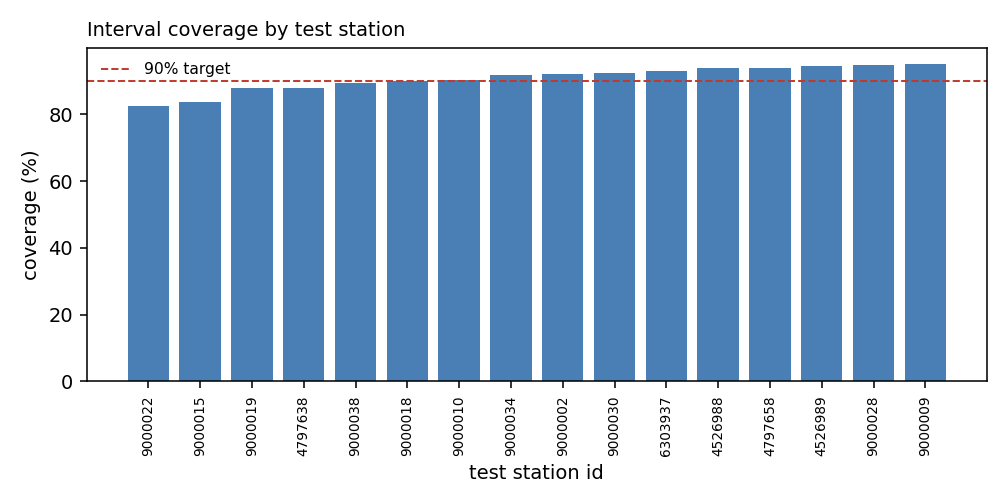

In [22]:
from IPython.display import Image, display
for f in ['shap_beeswarm.png','shap_waterfall.png','shap_importance.png','pred_vs_obs.png',
          'error_vs_concentration.png','accuracy_by_station.png','residual_hist.png',
          'timeseries_sample.png','geocp_coverage.png']:
    p = os.path.join('outputs/figures', f)
    if os.path.exists(p):
        print(f); display(Image(p, width=640))

## 10. 500 m pass (interval source)

Supplies the interval bounds only: the GeoCP weights depend on distance to the 13 calibration stations, so the field is smooth and can be computed on 3,696 cells then resampled to 10 m. Its map is not used.


In [23]:
# Two days for comparison: a clean one and a polluted one.
# The tile cache is keyed by extent+zoom, not by date, so both render with the same OSM background.
POLLUTED_DAY = '2025-08-30'    # network mean 33.0 ug/m3, max 173.0
LATEST_DAY   = '2026-10-14'    # the last complete day in the record (data ends 2026-10-15)
DATES = [POLLUTED_DAY, LATEST_DAY]

for d in DATES:
    print('=' * 74)
    print('rendering', d)
    !python run_pipeline.py --stage infer --date {d}


rendering 2025-08-30
stage: infer
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
Loading data...
Wrote /kaggle/working/urban-air/xgboost/data/sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
EDA cleaning: dropped 5292 sensor-floor rows (<= 0.5 ug/m3) (NYE masking off) (1,487,811 -> 1,482,519, 0.36% removed)
EDA window: kept rows from 2023-01-01 onward (1,482,519 -> 1,342,897, 9.4% removed)
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1323327, 24), y=(1323327,), unique groups=83
  deploying arm A, 18 features, fold 1's hyperparameters, n_estimators=298
  fitted on 794,073 rows from 54 training cells
  2025-08-30 08:00:00: 2147/3696 cells usable, mean stand-in coverage 1

## 13. Window sweep (off by default)

Four windows x five arms is ~7.5 h. Run it as its own commit, or from a shell: `python experiments/window_sweep.py --dry-run`.


In [24]:
# ---- cohort/window sweep: OPT-IN -----------------------------------------------------------------
RUN_WINDOW_SWEEP = False        # four windows x five arms is ~7.5 h; keep it off for the main commit

if not RUN_WINDOW_SWEEP:
    print('window sweep skipped (RUN_WINDOW_SWEEP = False).')
    print('run it with: python experiments/window_sweep.py --dry-run   then drop the --dry-run')
else:
    import pandas as pd
    !python experiments/window_sweep.py --arms A B C C+ TEXTURE --n-trials 60 --row-stride 4
    sweep = pd.read_csv('outputs/sweep/window_sweep.csv')
    print(sweep.pivot_table(index='arm', columns='window', values='pooled_r2').round(3).to_string())
    p = sweep.pivot_table(index='arm', columns='window', values='pooled_r2')
    if {'C', 'A'} <= set(p.index):
        print('\nC - A by window (near zero = the null survives):')
        print((p.loc['C'] - p.loc['A']).round(3).to_string())


window sweep skipped (RUN_WINDOW_SWEEP = False).
run it with: python experiments/window_sweep.py --dry-run   then drop the --dry-run


## 11. 10 m grid

One value per 10 m pixel (10,634,913) instead of 3,696 cells. Features are box statistics of the raster around each pixel and the stand-in history is streamed in row blocks, so no 10.6 M-row table is built. Each snapshot is a 4-band GeoTIFF: prediction, lower, upper, usable. About 12 minutes for both dates.


no CARTO_API_KEY: the basemap falls back to Esri tiles
stage: grid10
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
  patch stack: 2729 x 3897 px | window 32 px (320 m) | 255 MB in memory
    bh_mean              finite 100.0%  mean 2.633  sd 3.179
    bh_stdev             finite 100.0%  mean 2.425  sd 3.699
    ndvi_mean            finite 100.0%  mean 0.131  sd 0.305
    bldg_dens            finite 100.0%  mean 0.178  sd 0.205
    aspect_ratio_mean    finite 49.8%  mean 1.362  sd 1.208
    street_width_mean    finite 47.1%  mean 3.529  sd 1.294
  wrote /kaggle/working/urban-air/xgboost/data/patch_stack_10m.npz (133 MB)
done
stage: infer10
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
Loading data...
Wrote /kaggle/working/urban-air/xgboost/data/sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metri

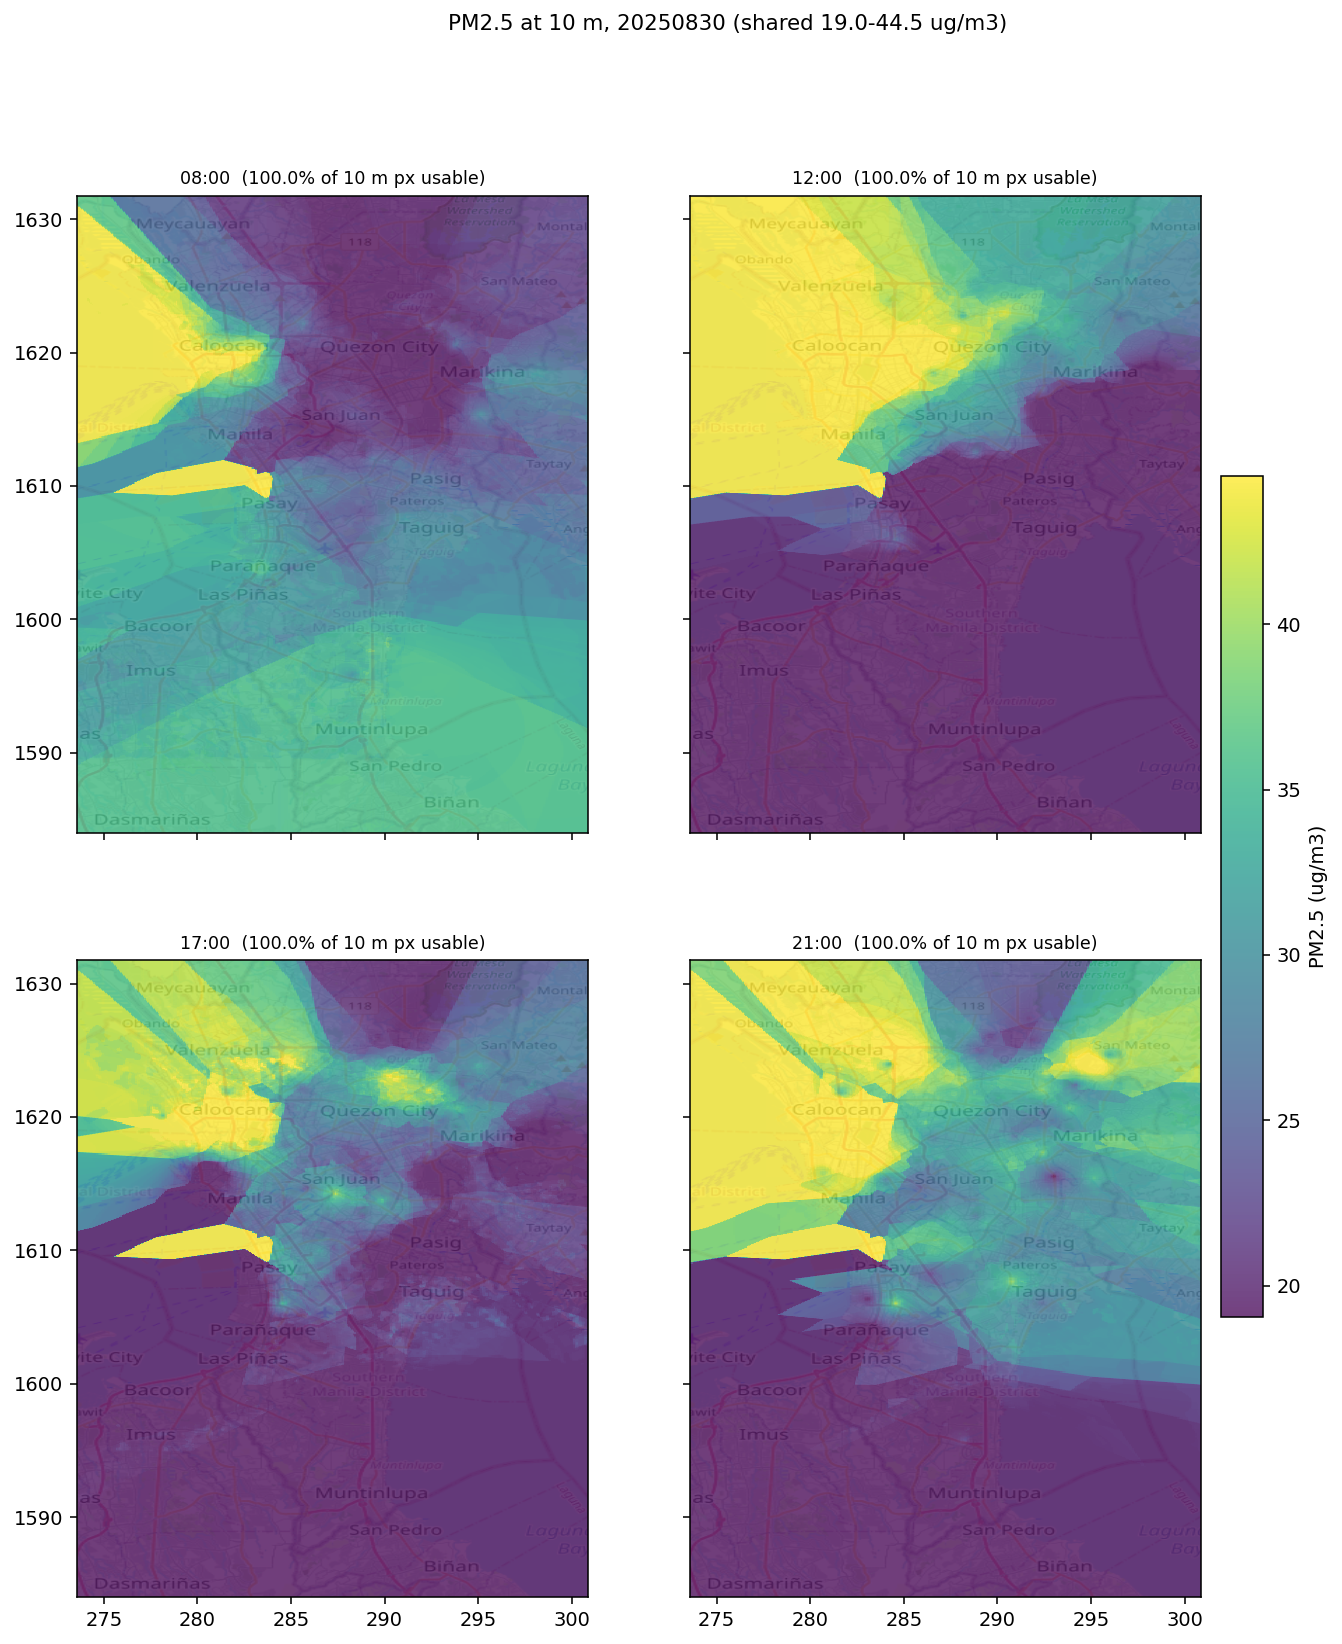

  boundary: 17 cities
  -> outputs/figures/exports/xgb_panels_20261014.png
2026-10-14   (10 m grid)
  pixels      : 13,030,975 | window: 32 px
  usable      : 13,030,975 - 13,030,975 per hour (100.0%)
  intervals   : interval bounds resampled bilinearly from the 500 m GeoCP field, not computed per pixel


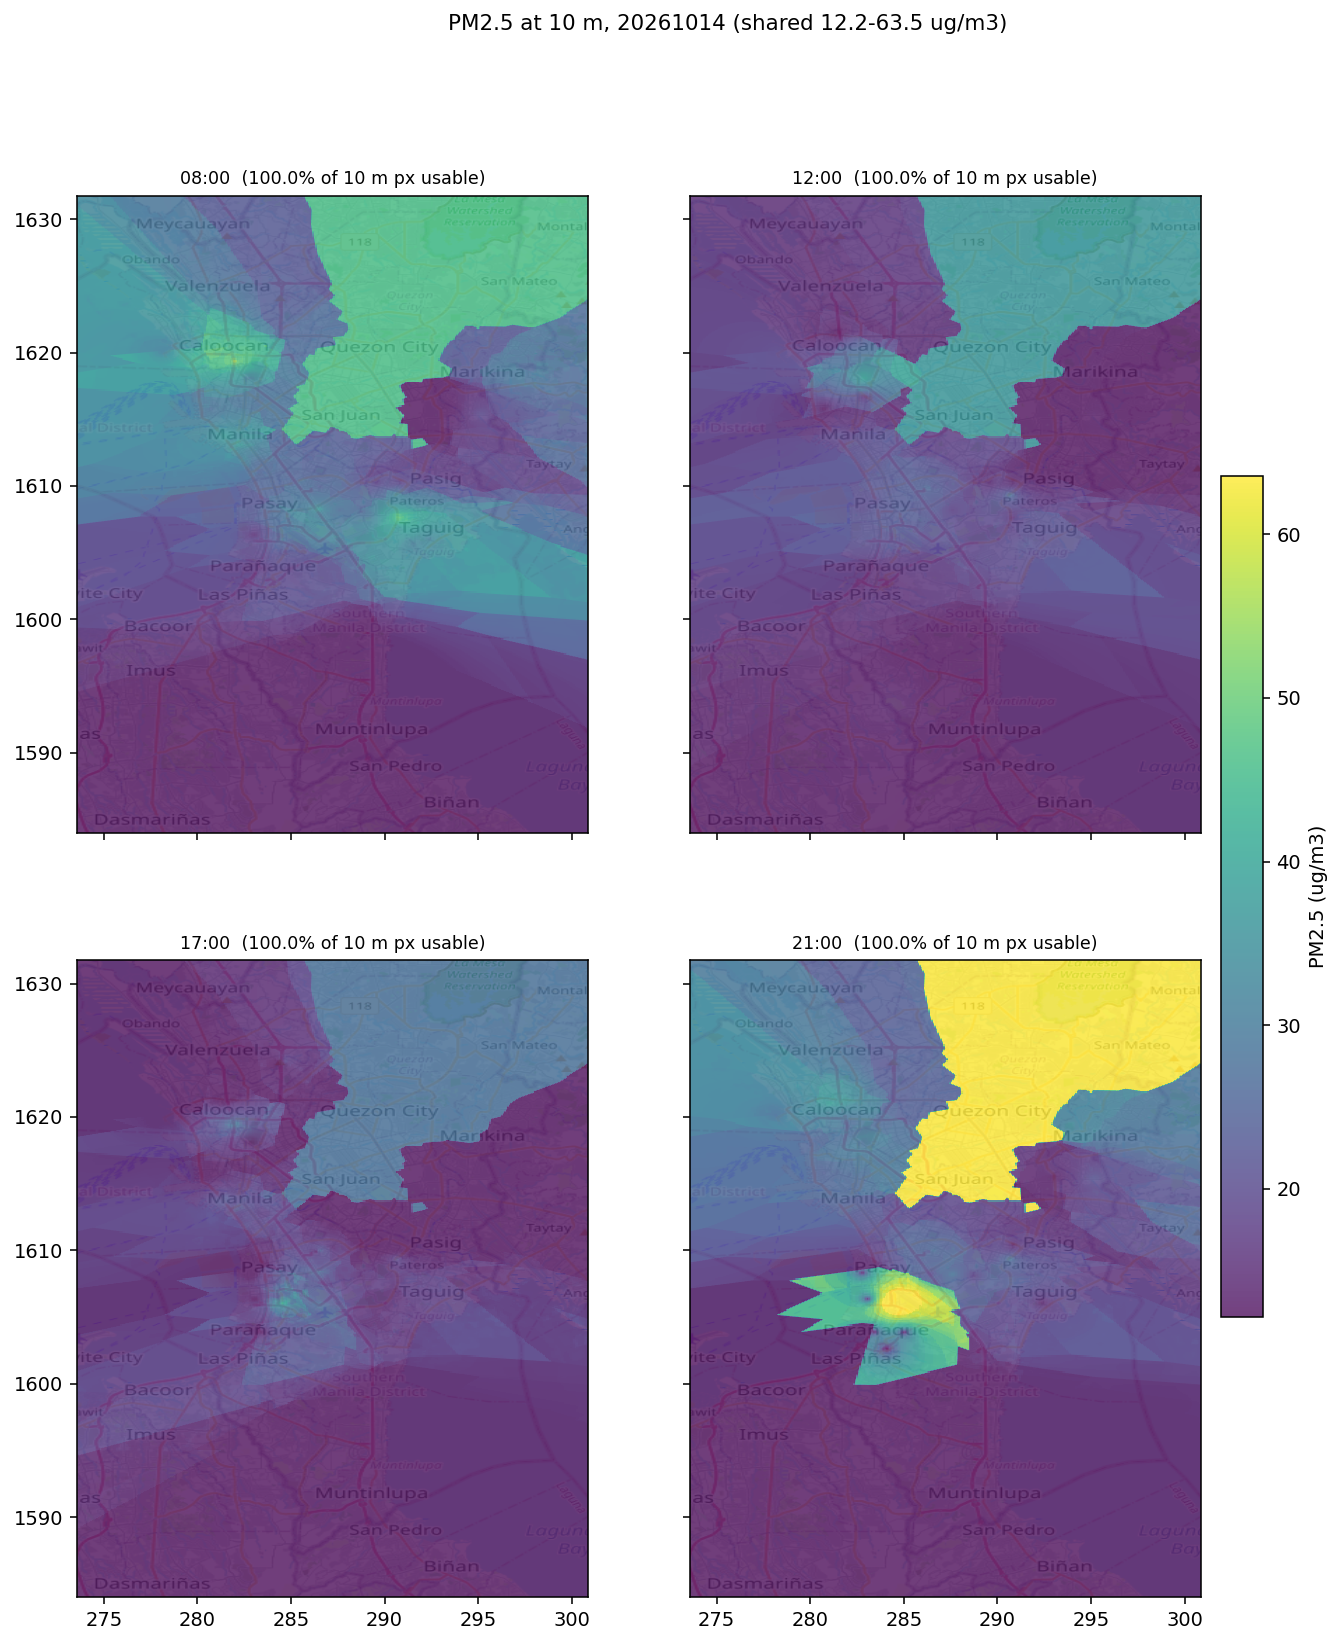

  boundary: 17 cities
  -> outputs/figures/exports/xgb_panels_20250830.png


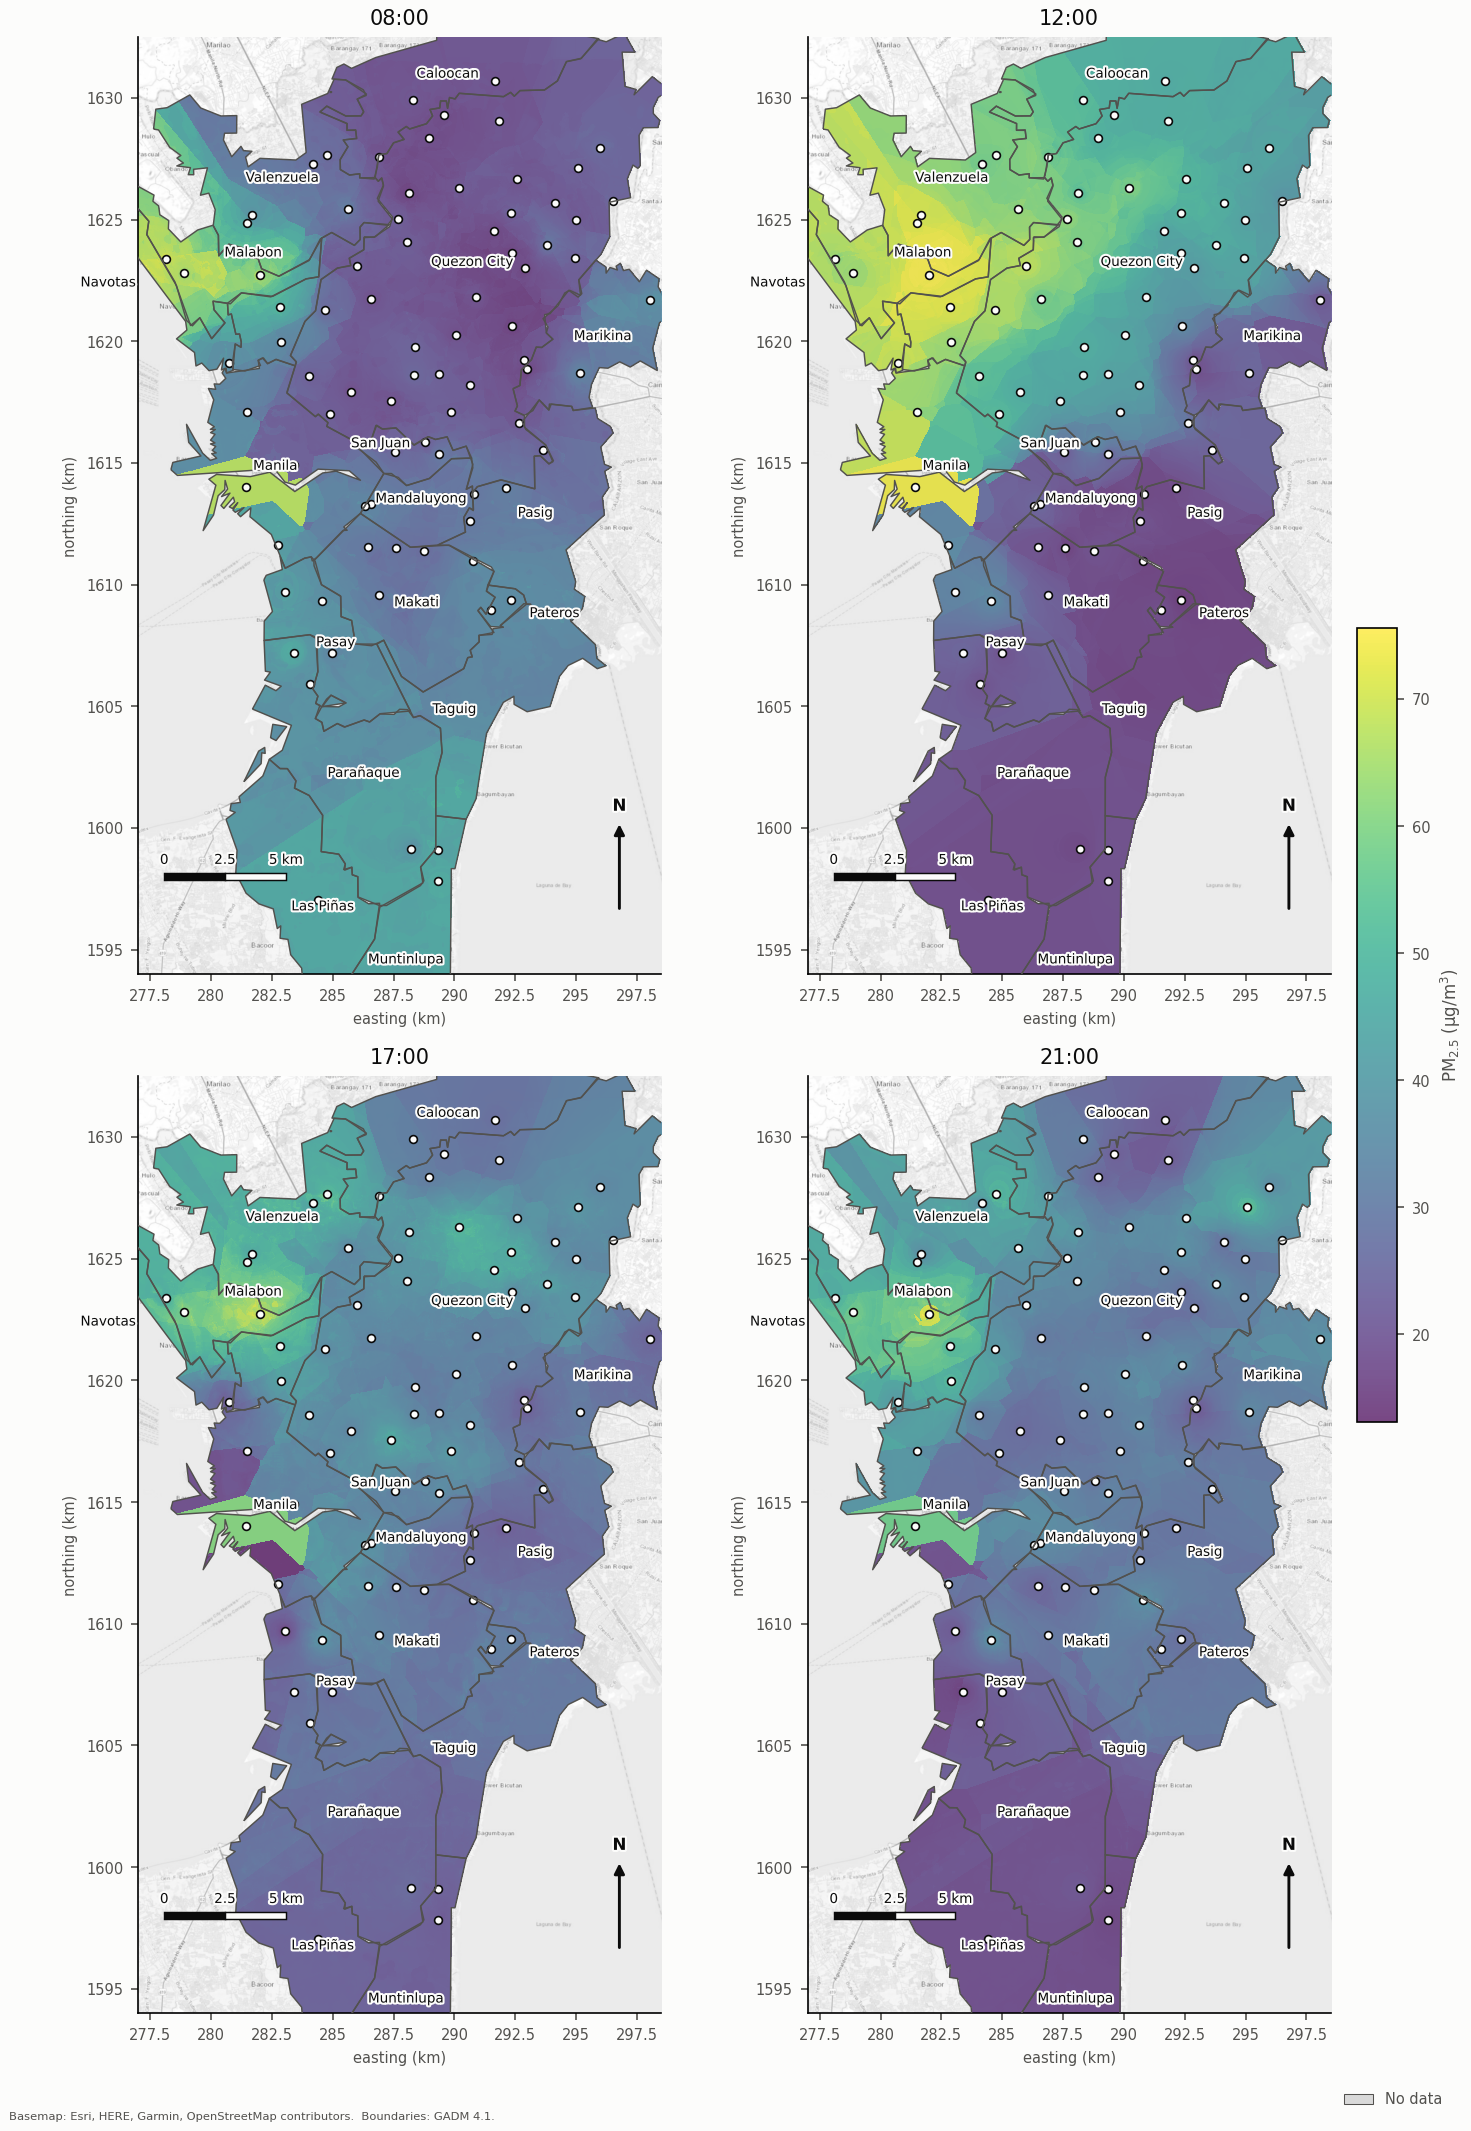

  boundary: 17 cities
  -> outputs/figures/exports/xgb_panels_20261014.png


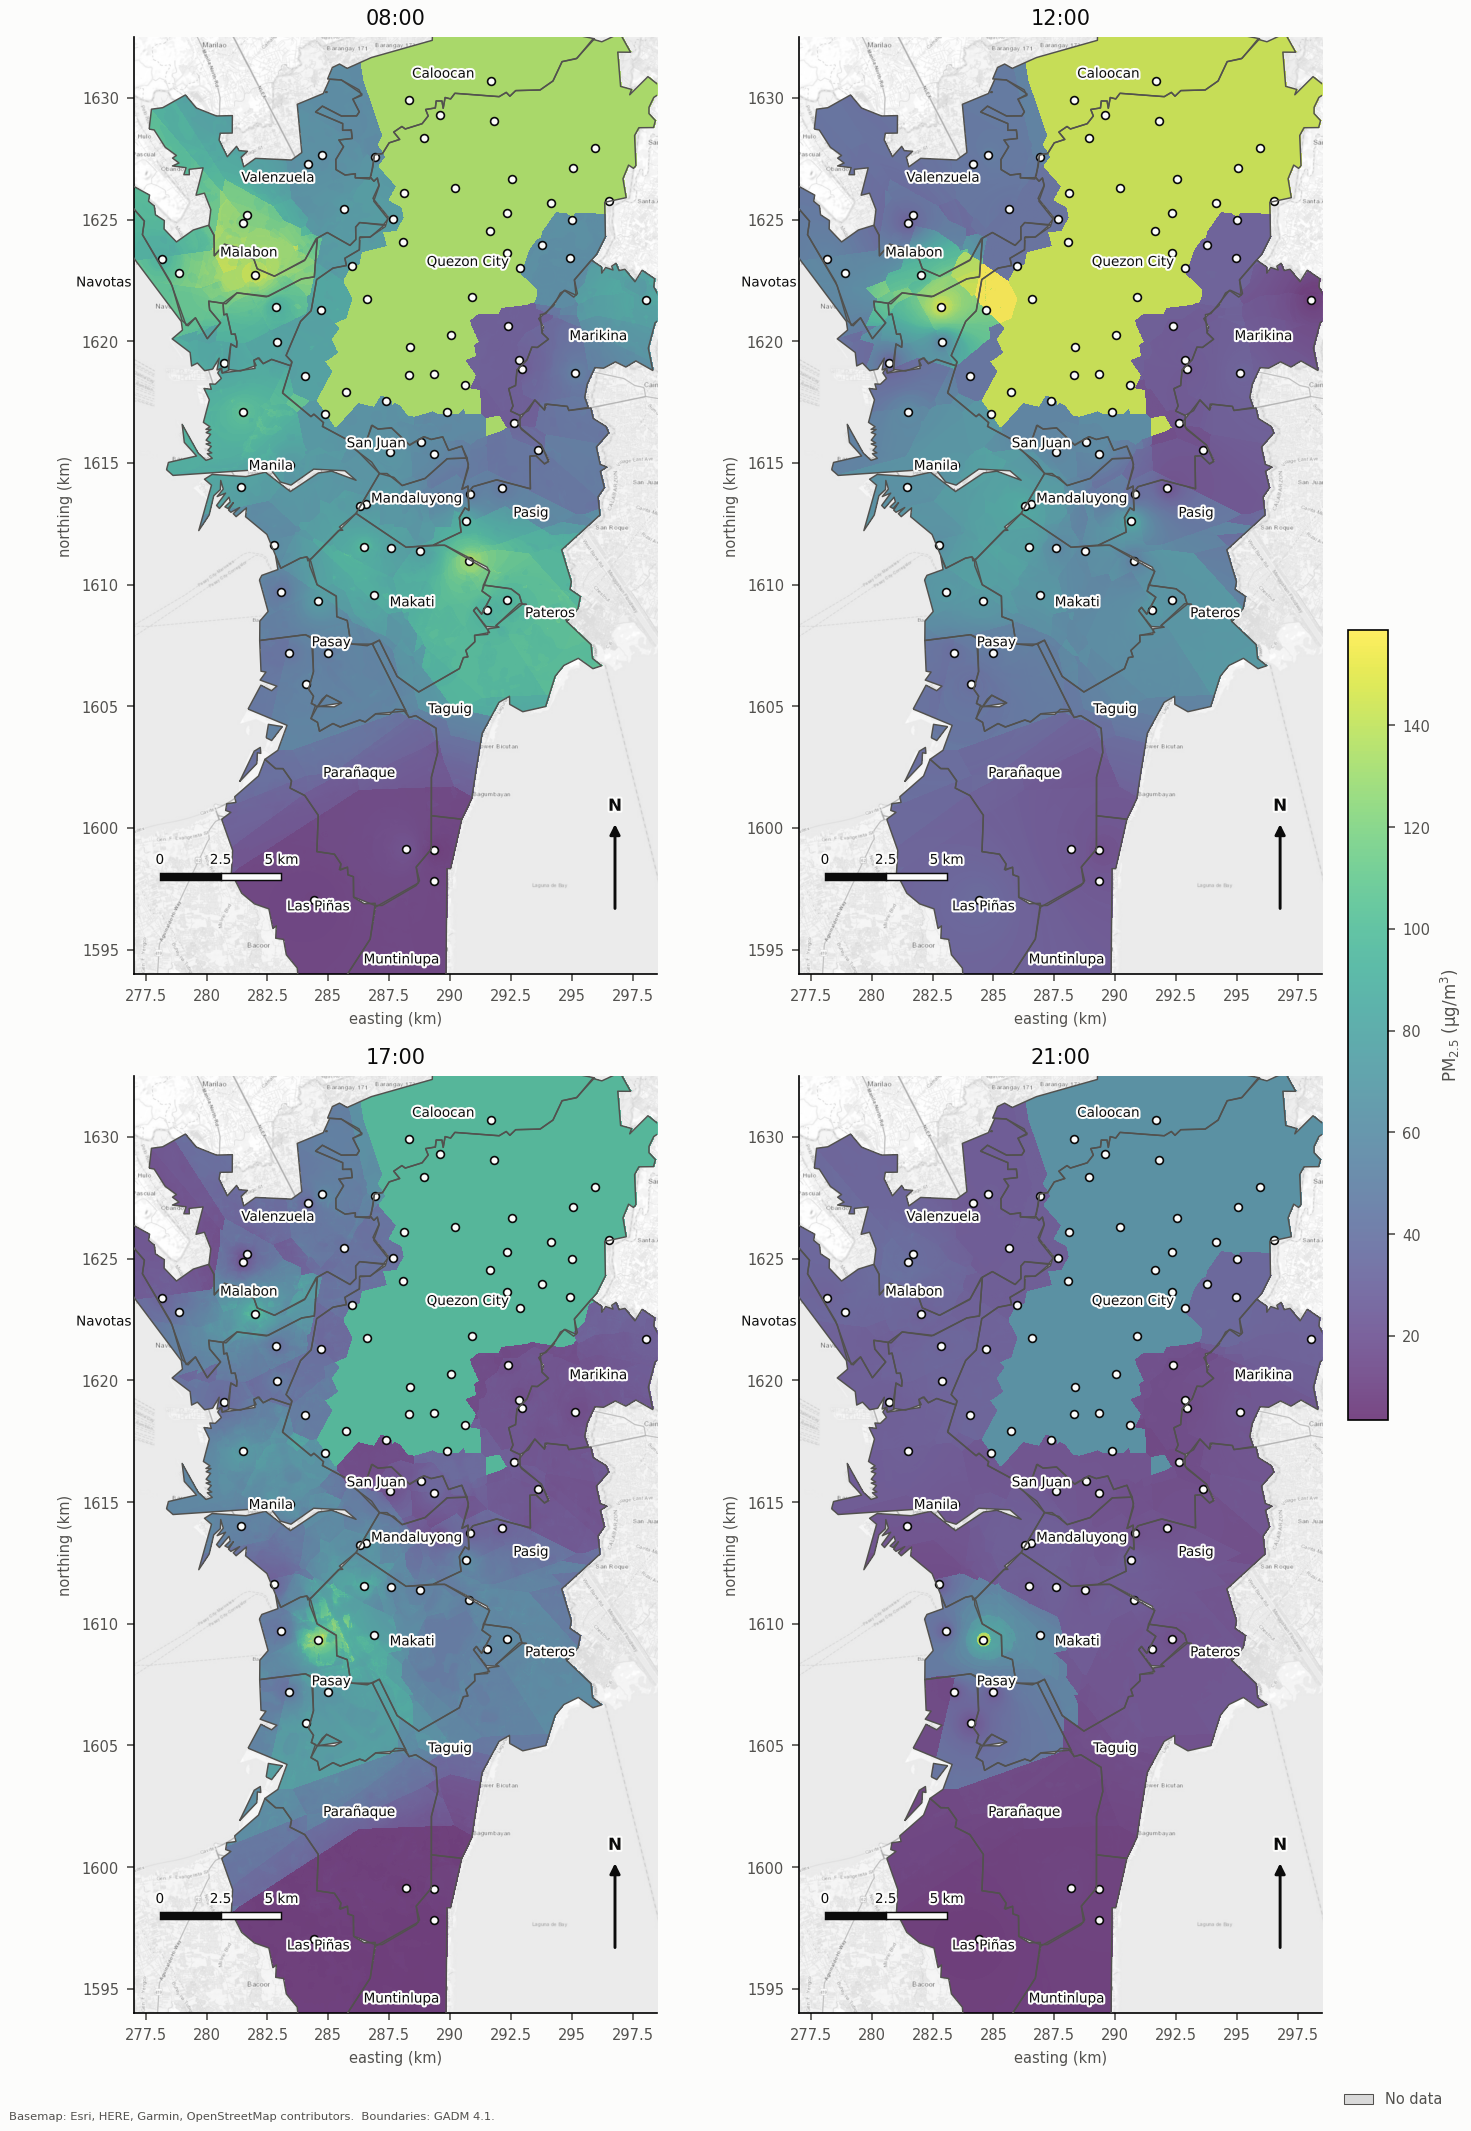

In [25]:
# ---- 10 m grid: opt-in (~12 min for both dates) --------------------------------------------------
RUN_10M = True          # the 10 m grid IS the deliverable; set False for a fast run
FILL_GAPS = True       # nearest-valid morphology + edge padding: paints the whole NCR

# The CNN-LSTM figures use CartoDB Positron through contextily, which needs a free CARTO key.
# Their pipeline reads it from Kaggle Secrets; do the same so the two figures share one basemap.
try:
    from kaggle_secrets import UserSecretsClient
    os.environ['CARTO_API_KEY'] = UserSecretsClient().get_secret('CARTO_API_KEY')
    print('CARTO_API_KEY set from Kaggle Secrets -> Positron basemap')
except Exception:
    print('no CARTO_API_KEY: the basemap falls back to Esri tiles')

if not RUN_10M:
    print('10 m grid skipped (RUN_10M = False).')
elif not globals().get('RASTER_OK', True):
    raise SystemExit('the 10 m grid needs master_raster_v2.tif, which is not on the dataset mount '
                     '(see the warning in cell 0)')
else:
    # 32 px windows at 10 m = 320 m, the same neighbourhood the CNN-LSTM branch samples
    _fill = ' --fill' if FILL_GAPS else ''
    !python run_pipeline.py --stage grid10 --window-px 32
    for d in DATES:
        !python run_pipeline.py --stage infer10 --date {d} --window-px 32{_fill}

    from IPython.display import Image, display
    import json as _json
    for d in DATES:
        day = d.replace('-', '')
        # the shared Positron basemap + the one colour scale both branches use
        !python maps/cnn_maps.py --days {day}
        print('=' * 74)
        print(d, '  (10 m grid)')
        s = _json.load(open(f'outputs/surfaces10m/{day}_summary.json'))
        lo = s.get('n_usable_min', s.get('n_usable'))
        hi = s.get('n_usable_max', s.get('n_usable'))
        n_h = max(1, len(s.get('hours', [])) or 4)
        pct = (100 * s['usable_fraction'] if 'usable_fraction' in s
               else 100.0 * lo / (s['n_pixels'] * n_h))
        print('  pixels      :', f"{s['n_pixels']:,}", '| window:', s['window_px'], 'px')
        print('  usable      :', f"{lo:,} - {hi:,}", 'per hour (%.1f%%)' % pct)
        print('  intervals   :', s['note'])
        p = f'outputs/surfaces10m/panel_10m_{day}.png'
        display(Image(p, width=760))

    # the same maps in the CNN-LSTM cartography: basemap, NCR clip, city names, matched colour scale
    for d in DATES:
        day = d.replace('-', '')
        # the shared Positron basemap + the one colour scale both branches use
        !python maps/cnn_maps.py --days {day}
        display(Image(f'outputs/figures/exports/xgb_panels_{day}.png', width=760))


## 12. Verification

Every arm scored on the 16 reserved test stations, then two checks that read the saved outputs. `--stage checks` is avoided because it also re-executes this notebook.


In [26]:
# ---- re-derive the headline numbers from what this run wrote -----------------------------------
import glob, subprocess, sys

for _a in ('A', 'B', 'C', 'C+', 'TEXTURE'):
    subprocess.run([sys.executable, 'run_pipeline.py', '--stage', 'test', '--test-arm', _a], check=True)

# root-level figures (arm_comparison + the shap json the summary reads)
subprocess.run([sys.executable, 'run_pipeline.py', '--stage', 'figures'], check=True)

import pandas as pd
abl = pd.read_csv('outputs/ablation_summary.csv')
test = pd.read_csv('outputs/test_metrics_all.csv')

print('=== out-of-fold, training cells only (nested spatial CV) ===')
print(abl.sort_values('pooled_r2', ascending=False)
      [['arm', 'label', 'n_features', 'pooled_r2', 'r2_mean', 'r2_sd', 'pooled_rmse', 'pooled_mae']]
      .round(3).to_string(index=False))

print('\n=== the 16 reserved test stations (never fitted, tuned or calibrated on) ===')
cols = ['arm', 'stations', 'r2'] + [c for c in ('r2_seed_sd',) if c in test.columns] + \
       ['rmse', 'mae', 'bias', 'within_5', 'within_10']
print(test.sort_values('r2', ascending=False)[cols].round(3).to_string(index=False))
if 'r2_seed_sd' in test.columns:
    print('\nr2_seed_sd is the spread of the per-seed R2 -- the ensemble is the reported r2')

print('\n=== agreement between the two views ===')
best_t = test.sort_values('r2', ascending=False)['arm'].iloc[0]
best_o = abl.sort_values('pooled_r2', ascending=False)['arm'].iloc[0]
print('best on test stations : %s' % best_t)
print('best out-of-fold      : %s' % best_o)
print('same arm             : %s' % (best_t == best_o))

# Only the checks that finish in seconds. Timed on this machine:
#   verify_ablation.py          50 s   <- recomputes R2 from the out-of-fold predictions
#   check_morphology_coverage.py 7 s
#   verify_geocp.py            >150 s  (repeats the whole LOSO search)
#   verify_shared_split.py     >25 min (recomputes the raster patch statistics)
# Run the slow two by hand when you want them; they are not worth stalling a commit for.
FAILED = []
for _s in ('verify_ablation.py', 'check_morphology_coverage.py'):
    try:
        _r = subprocess.run([sys.executable, 'checks/' + _s], capture_output=True, text=True,
                            timeout=600)
        ok, _out = _r.returncode == 0, (_r.stdout or _r.stderr)
    except subprocess.TimeoutExpired:
        ok, _out = False, 'timed out after 600 s'
    print('\n--- %-32s %s' % (_s, 'ok' if ok else 'FAILED'))
    print(_out.strip()[-800:])
    if not ok:
        FAILED.append(_s)
print('\nVERIFICATION:', 'all checks passed' if not FAILED else 'FAILED -> %s' % FAILED)


stage: test
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
Loading data...
Wrote /kaggle/working/urban-air/xgboost/data/sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
EDA cleaning: dropped 5292 sensor-floor rows (<= 0.5 ug/m3) (NYE masking off) (1,487,811 -> 1,482,519, 0.36% removed)
EDA window: kept rows from 2023-01-01 onward (1,482,519 -> 1,342,897, 9.4% removed)
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1323327, 24), y=(1323327,), unique groups=83
arm A: fitting on 54 training cells (794,073 rows), scoring 16 test cells (293,957 rows)
  hyperparameters: {'colsample_bytree': 0.762, 'gamma': 0.233, 'learning_rate': 0.039, 'max_depth': 4, 'min_child_weight': 1.0,

## 14. Summary


In [27]:
import glob
print('network      :', df_clean['Grid_ID'].nunique(), 'cells /', df_clean['Location'].nunique(),
      'stations,', f'{len(df_clean):,}', 'rows')
print('winning arm  :', BEST, '(%d features)' % len(ARM_FEATURES[BEST]))
t = pd.read_csv('outputs/test_metrics_all.csv').set_index('arm').loc[BEST]
print('test stations: R² %.3f | MAE %.3f | RMSE %.3f | bias %+.3f'
      % (t['r2'], t['mae'], t['rmse'], t['bias']))
print('intervals    : coverage %.3f (target %.2f), width %.1f µg/m³'
      % (g['test']['coverage'], g['test']['target_coverage'], g['test']['mean_width']))
# --figures-arm writes into outputs/figures/<arm>/, so look there too instead of assuming the root
_shap_hits = sorted(glob.glob('outputs/figures/**/shap_importance.json', recursive=True),
                    key=lambda p: (BEST not in p, p))
_morph_shap = (json.load(open(_shap_hits[0], encoding='utf-8'))['families_pct'].get('morphology', 0.0)
               if _shap_hits else float('nan'))
print('morphology   : %.1f%% of gain, %.1f%% of SHAP attribution  (%s)'
      % (morph_share, _morph_shap, _shap_hits[0] if _shap_hits else 'no shap json found'))

network      : 83 cells / 84 stations, 1,323,327 rows
winning arm  : A (18 features)
test stations: R² 0.660 | MAE 3.463 | RMSE 6.553 | bias +0.629
intervals    : coverage 0.904 (target 0.90), width 15.3 µg/m³
morphology   : 0.0% of gain, 2.6% of SHAP attribution  (outputs/figures/A/shap_importance.json)
